# going to make it so that it loads 3 hours instead of just 1
should be able to scale from there

In [1]:
import sunpy
import sunpy.timeseries 
from sunpy.net import Fido, attrs as a
import matplotlib.pyplot as plt
import sunpy.map
import numpy as np
import webbrowser
from pathlib import Path
from urllib.request import urlretrieve
from astropy.io import fits
from datetime import date
import time
from astropy.time import Time
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from astropy.visualization import time_support
from sunpy import timeseries as ts
import csv
import pandas as pd

/Users/scottd/miniforge3/envs/sunpy-clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Things needing done,
flares tha occur near the hour mark need to have 2 files loaded and combined 

if 2 flares occur within 10 minuets the smaller one needs tossed or both need removed since i am unsure how each line is tempurature sensitive

need to identify which lines are flare sensitive too


need to figure out how to find the enhancement rather than flat value

looks like i should be making it EVE L4 data instead 
        level 2 is every 10 second readings
        level 4 is every 1 minute average

# Part 1
## Flare locating with properties

In [ ]:
hek_results = result["hek"]

debugging=0

t1=s1=e1=0
p=0
q=0
with open('flares_data.csv', 'w', newline='') as csvfile:
    spamwriter = csv.writer(csvfile, delimiter=',', quotechar='|', quoting=csv.QUOTE_MINIMAL)

    spamwriter.writerow(['Flare', 'event_starttime', 'event_peaktime','event_endtime',
                                 'flare_class','hgs_x','hgs_y','distance from disk',
                                 'EVE_file','XRS_file'
                                ])
    
    
    for i, flare in enumerate(hek_results):


        if np.sqrt(((float(flare['hgs_x'])**2)+(float(flare['hgs_y'])**2)))==0:
            p+=1
            continue


        t=flare['event_peaktime']; s=flare['event_starttime'];e=flare['event_endtime']
        if t==t1 or s==s1 or e==e1:
            q+=1
            # will probably want 
            continue
            
        t1=t ; s1=s ; e1=e
        
                                                                    ####### make a loop here that runs three times for each past and future too then make a check 
                                                                    ####### to see if file is already downloaded before downloading ,but should always write it to file
        year=int(t.ymdhms.year); month=int(t.ymdhms.month); day=int(t.ymdhms.day); hour=int(t.ymdhms.hour)
        day_of_year = date(year, month, day).timetuple().tm_yday    
        version = 8; revision = 1
        prefix = "EVL"  # EVL = lines; EVS = spectra
        filename = (f"{prefix}_L2_{year}{day_of_year:03d}_{hour:02d}_"
                     f"{version:03d}_{revision:02d}.fit.gz")
    
        
        url = ("https://lasp.colorado.edu/eve/data_access/"
        f"evewebdata/products/level2/{year}/{day_of_year:03d}/{filename}")


        if debugging==0:    
            webbrowser.open(url)


                                                                                ########### also make a check the the flare isnt too close to mid night for Xrays 
        
            result = Fido.search(a.Time(f'{year}-{month}-{day} {hour}:00', f'{year}-{month}-{day} {hour}:01'), a.Instrument("XRS"),  a.Resolution("flx1s"))
            XRay_file = Fido.fetch(result, path='./GOES_XRS_Data/')

        else:
            XRay_file=[0] #for debugging
        
    
        spamwriter.writerow([i, flare['event_starttime'], flare['event_peaktime'],flare['event_endtime'],
                                 flare['fl_goescls'],flare['hgs_x'],flare['hgs_y'],(np.sqrt(((float(flare['hgs_x'])**2)+(float(flare['hgs_y'])**2)))),
                                 filename,XRay_file[0]])
            
    
        

        print(i)
    
print(p)
print(q)

In [4]:
print('done')

done


# part 2

In [3]:
start_times=[]
end_times=[]
peak_time=[]
xrayfilename=[] # has more file path in save
evefilename=[]
radius=[]
flare_class=[]

with open("flares_data.csv", "r", newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        start_times.append(row["event_starttime"])
        end_times.append(row["event_endtime"])
        peak_time.append(row["event_peaktime"])
        xrayfilename.append(row["XRS_file"])
        evefilename.append(row["EVE_file"])
        radius.append(row["distance from disk"])
        flare_class.append(row["flare_class"])

In [4]:
def time_add(date_string, time_change):

    dt = datetime.strptime(date_string, '%Y-%m-%d %H:%M:%S.%f')
    new_dt = dt + timedelta(minutes=time_change)
    
    result = new_dt.strftime('%Y-%m-%d %H:%M:%S.%f')

    return result


## want to only use flares in middle of hour for now to avould having to load multiple files per flare

also need way to identify if the emission flux is elivated due to flare or not or if its always just the same ones then we can just hard filter them

also next step is to add them to add the max fluxes to the CSV file as 50 extra coloumns 


have a look at flares 170 to 175

360
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

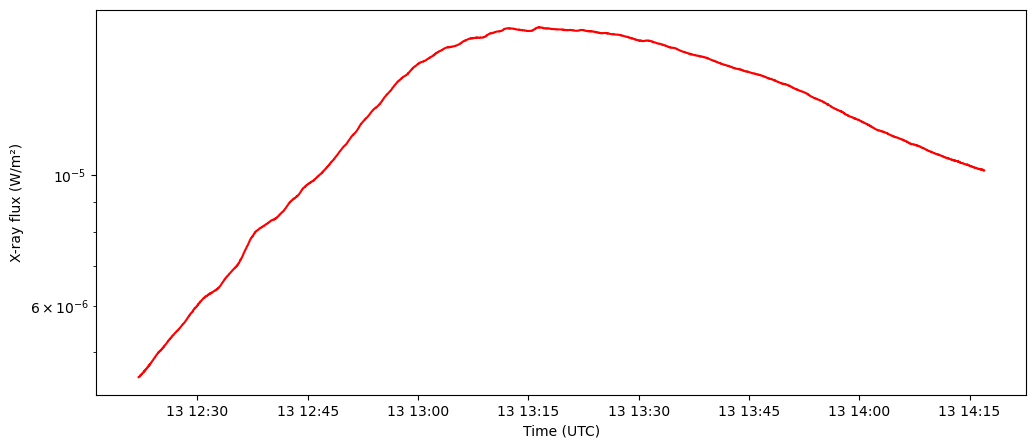

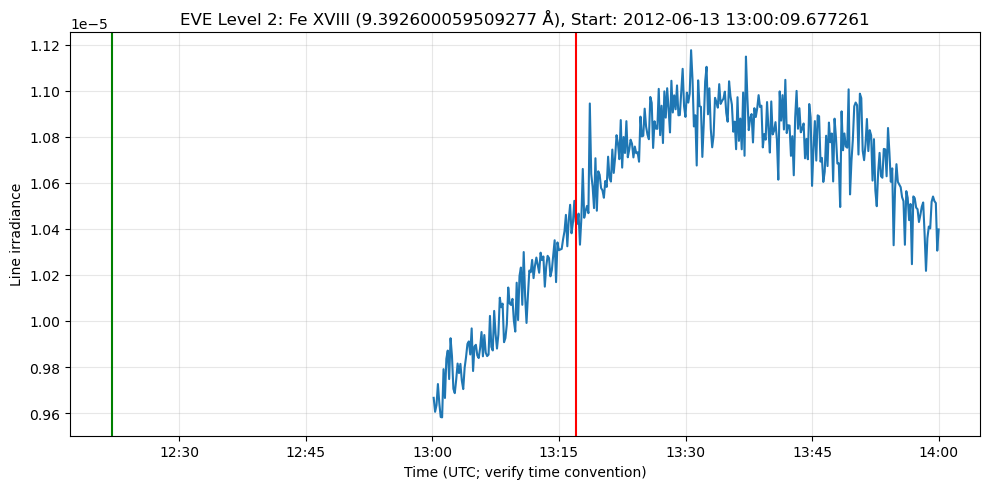

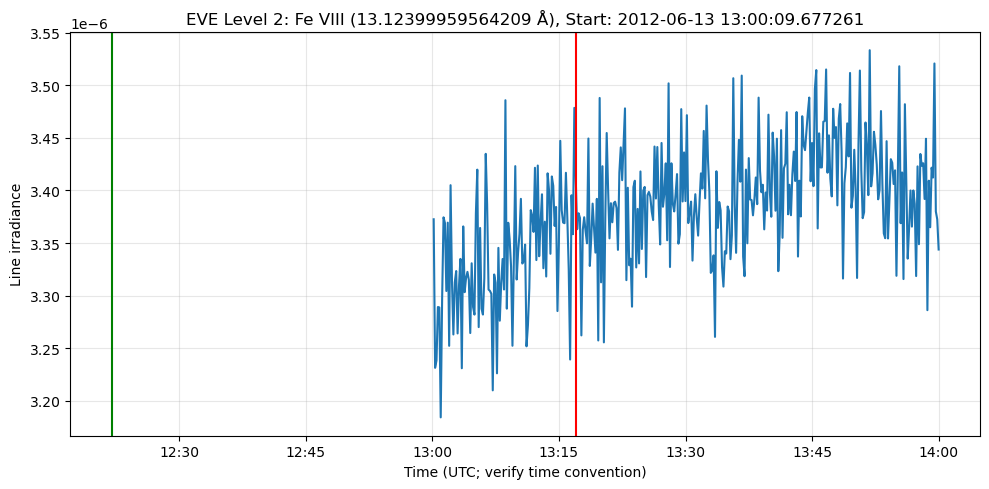

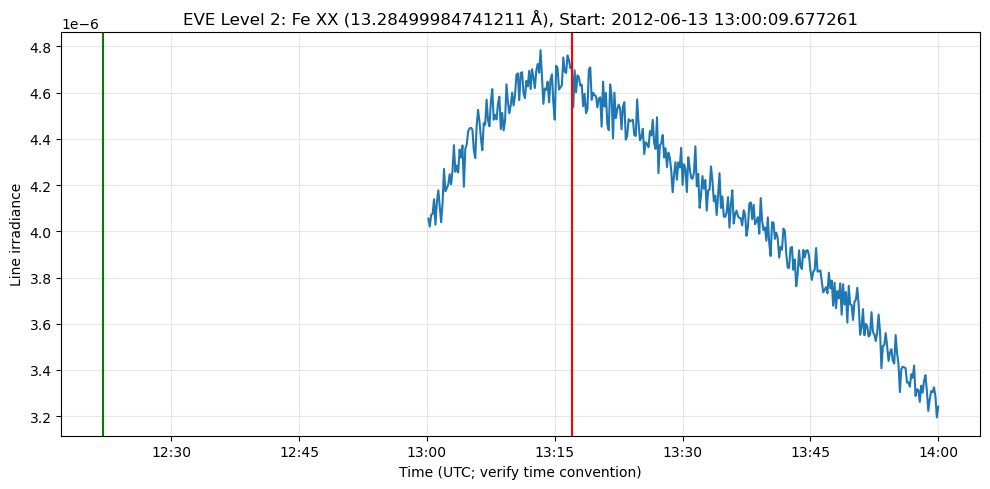

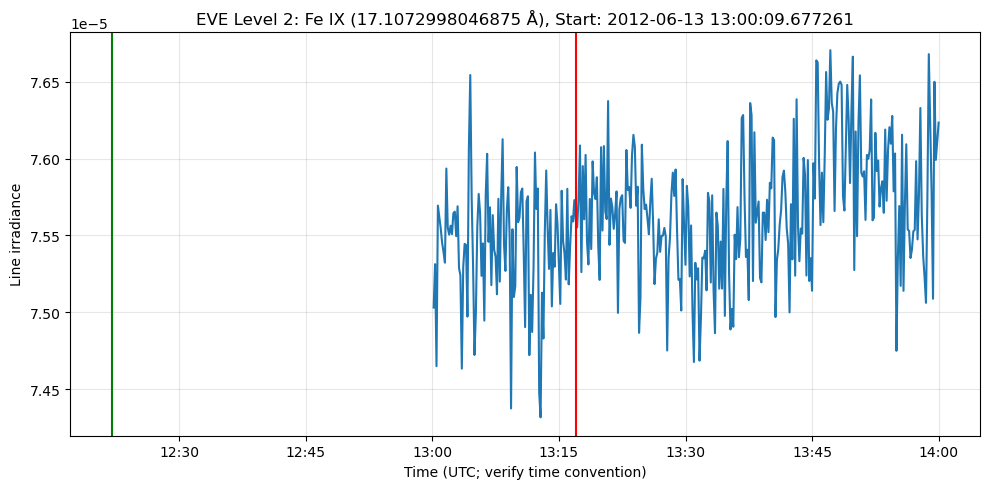

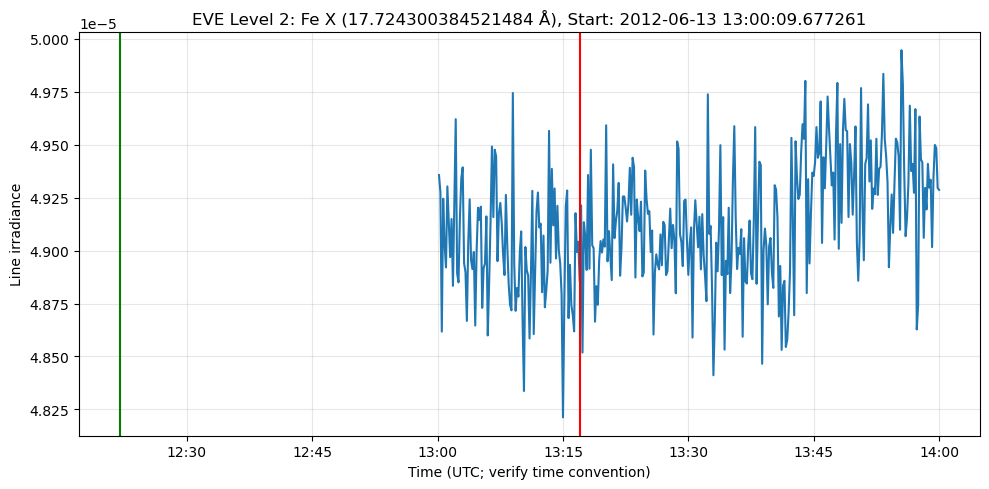

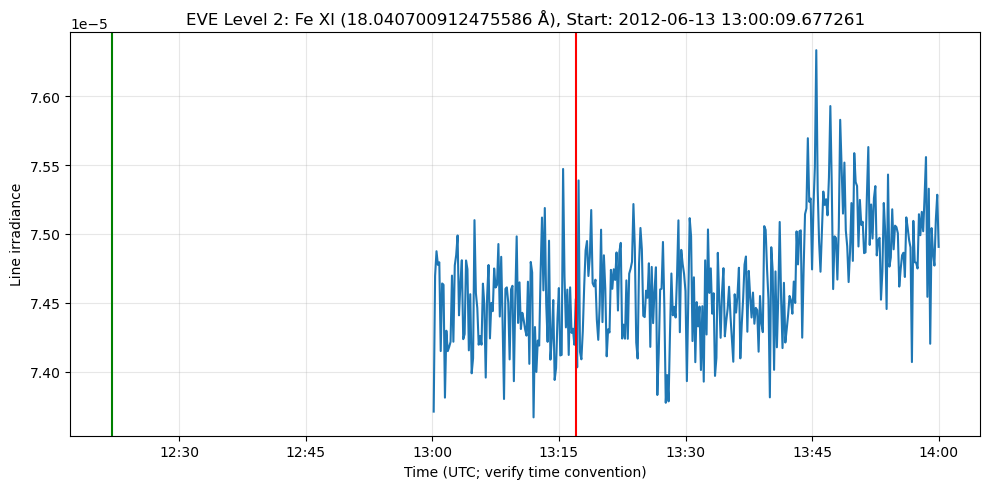

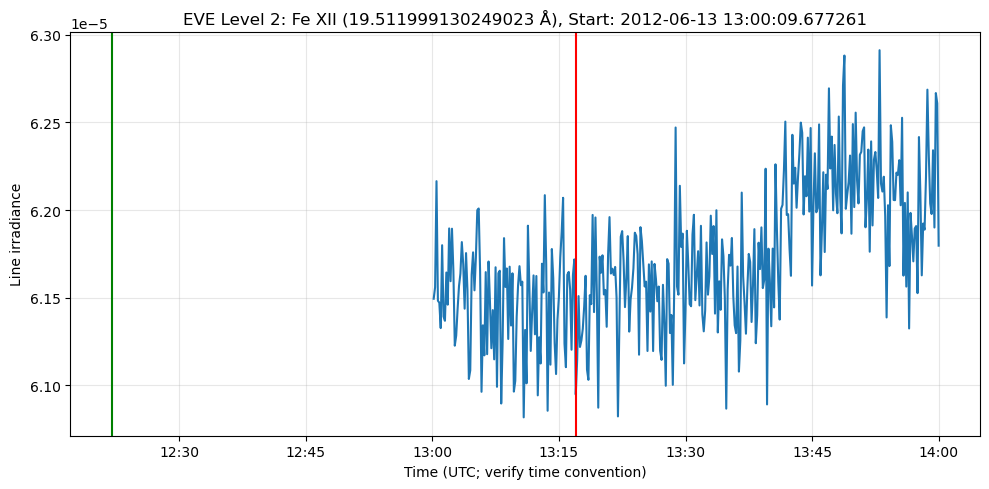

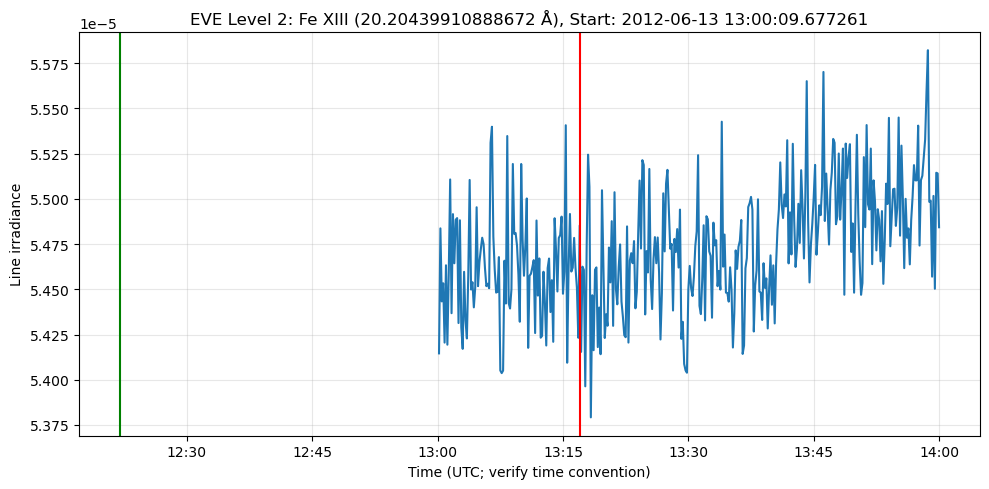

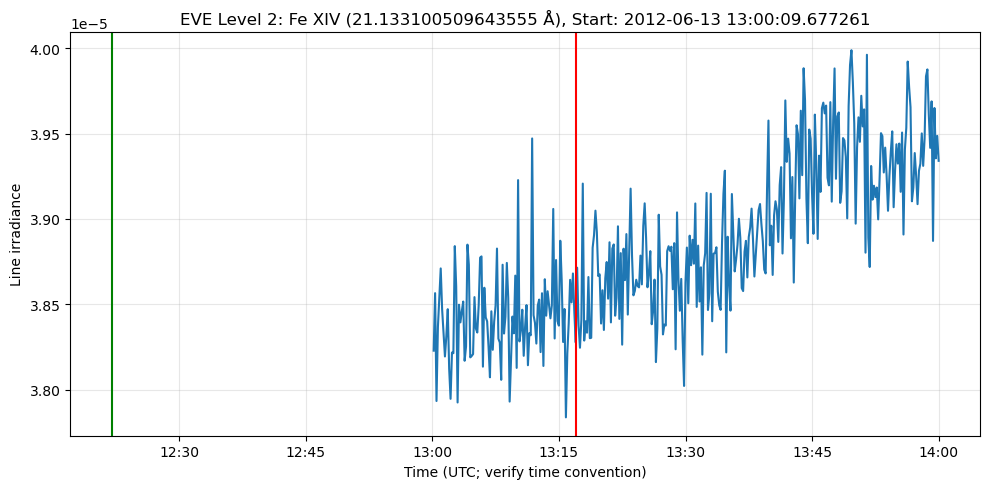

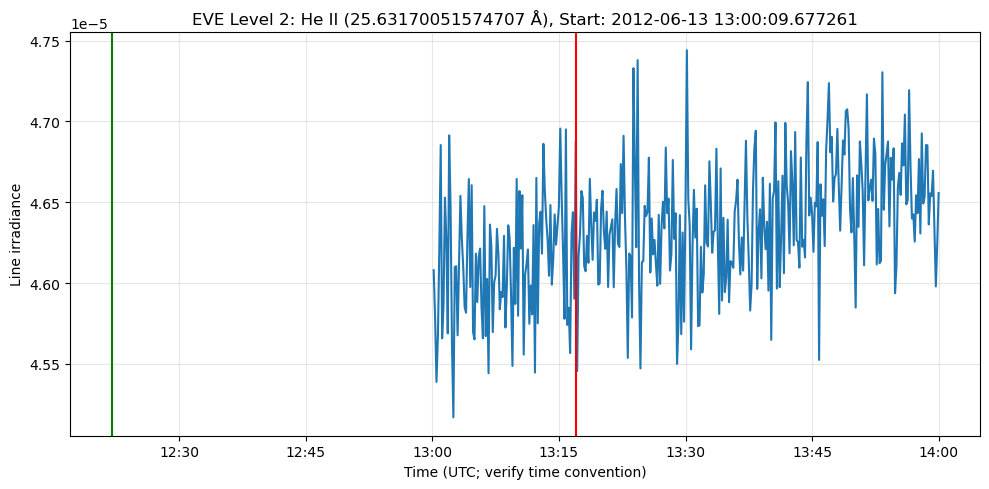

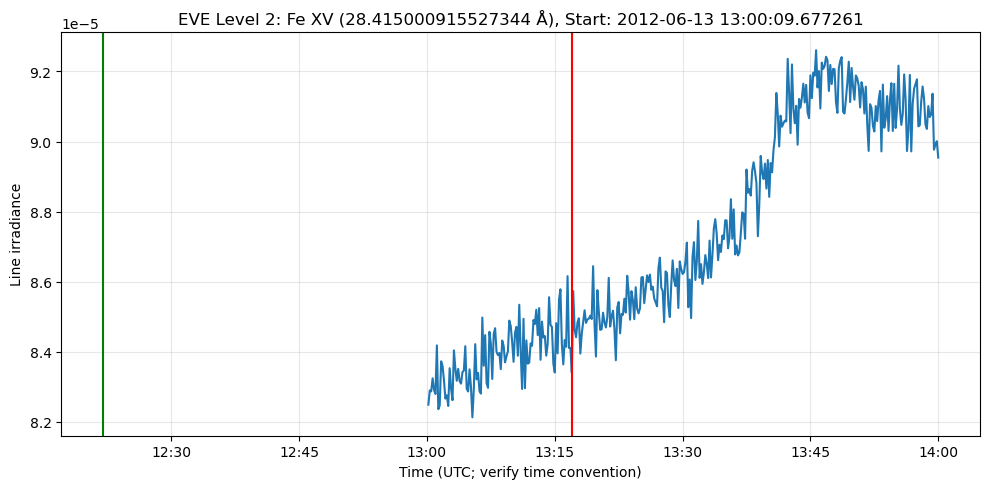

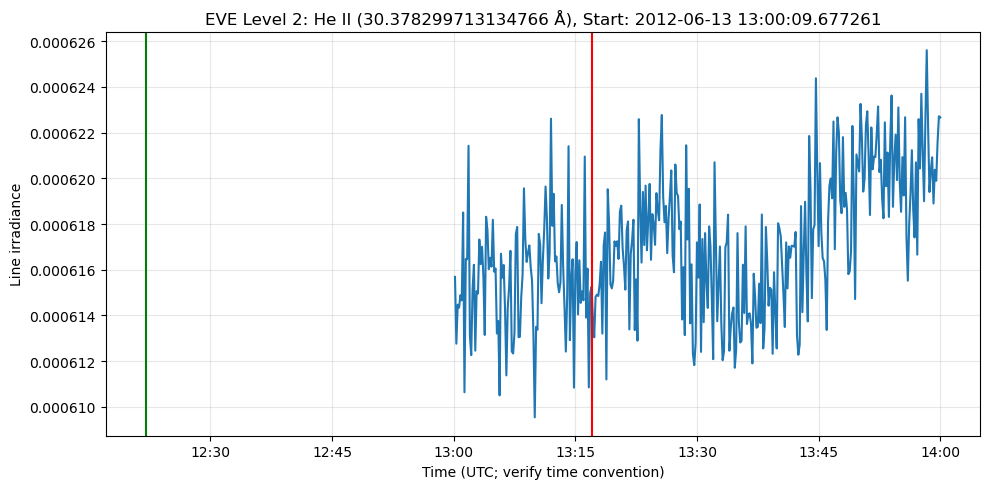

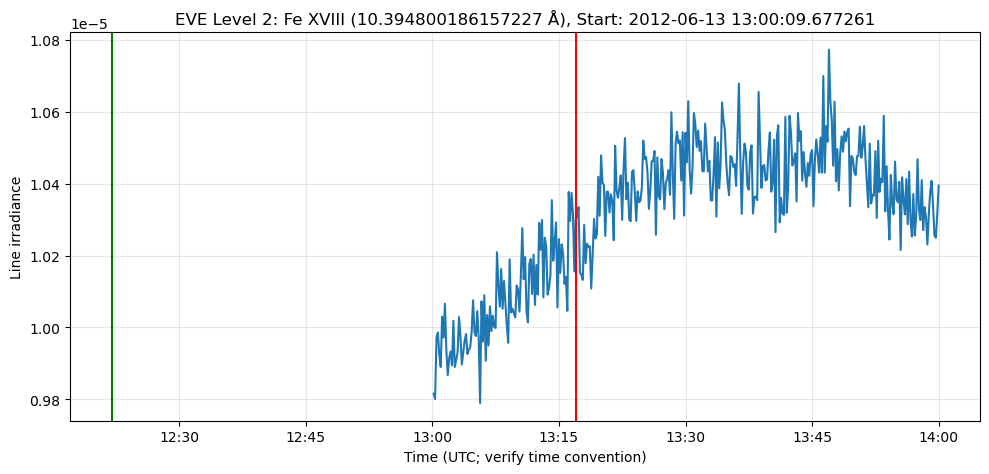

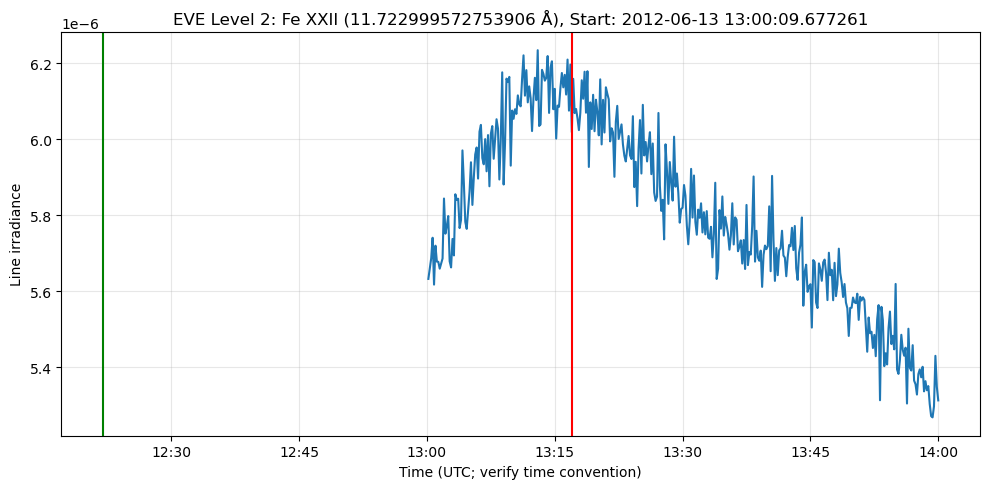

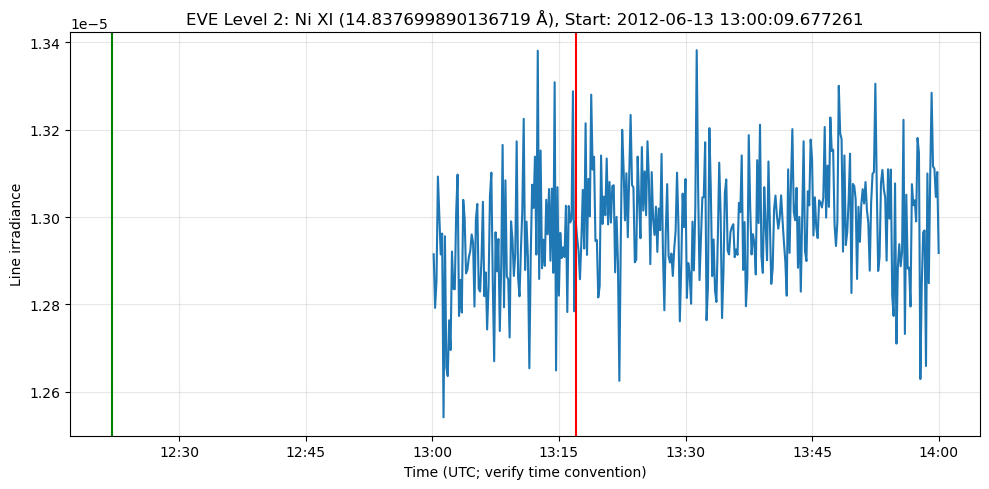

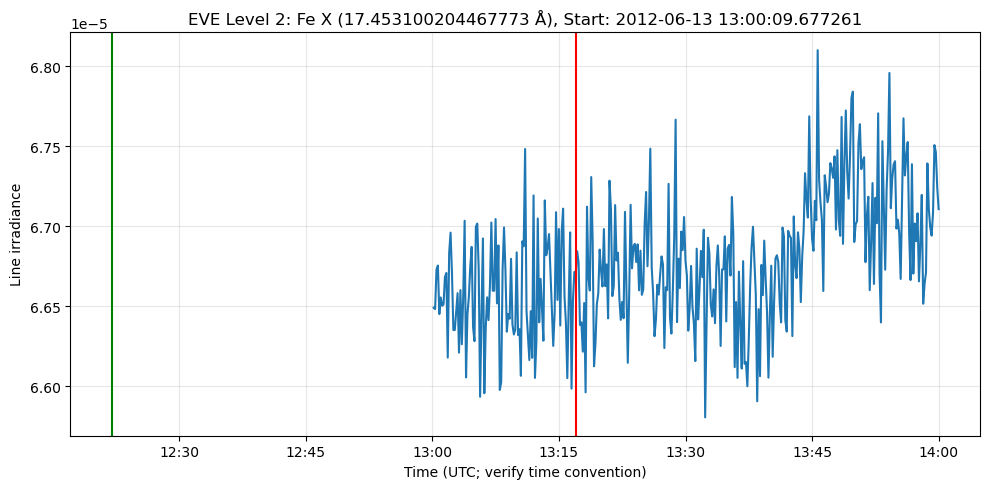

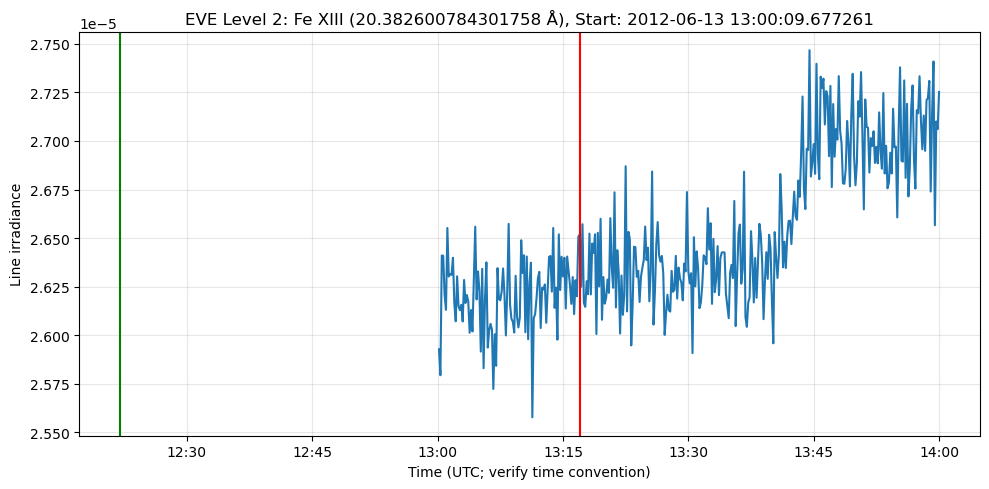

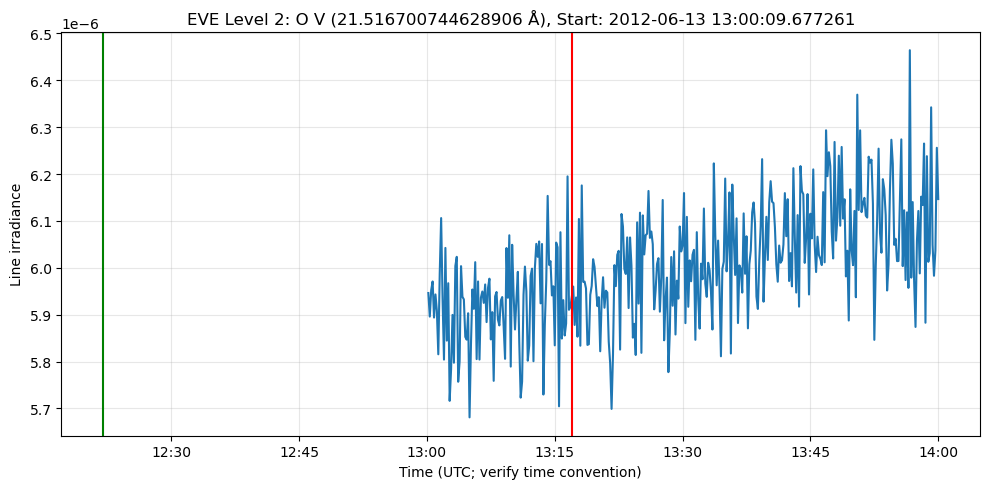

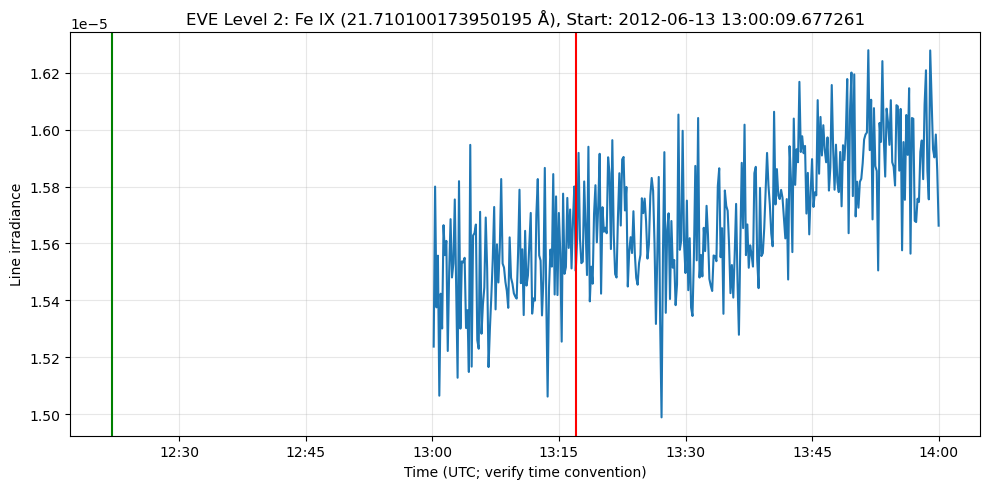

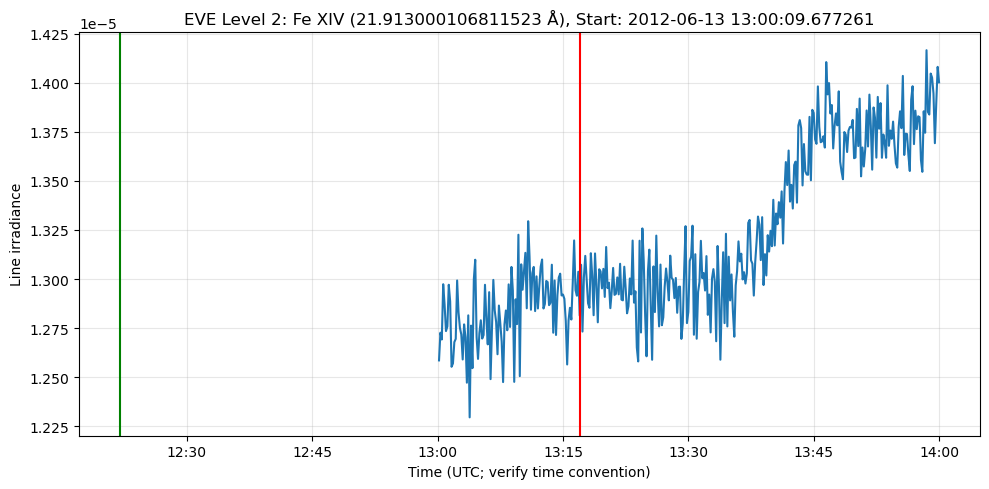

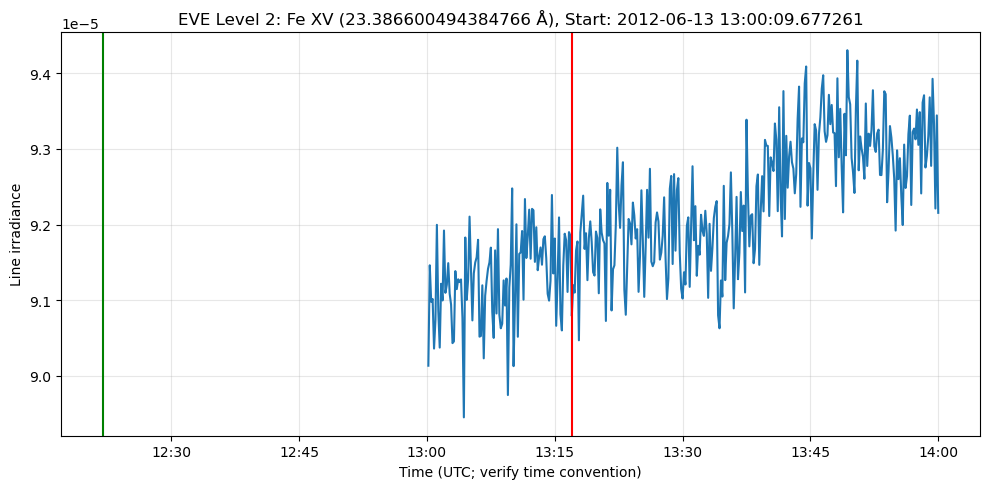

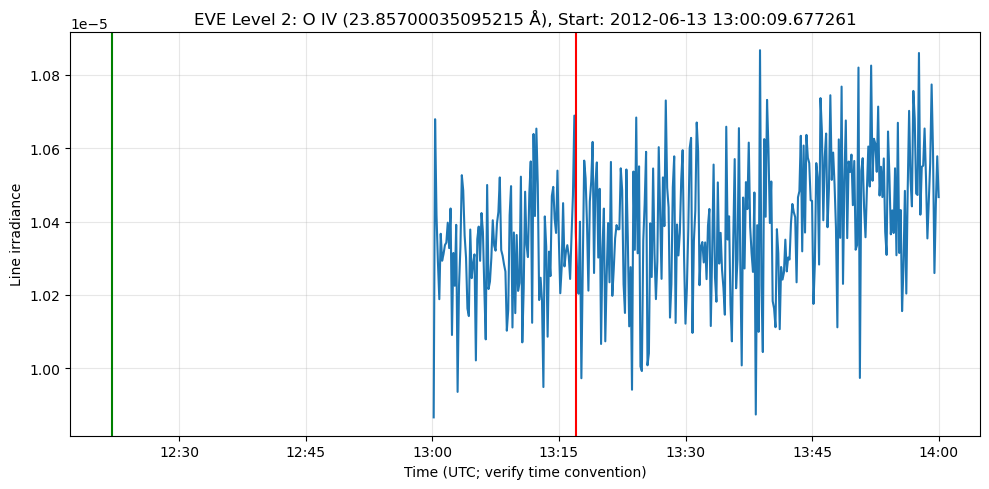

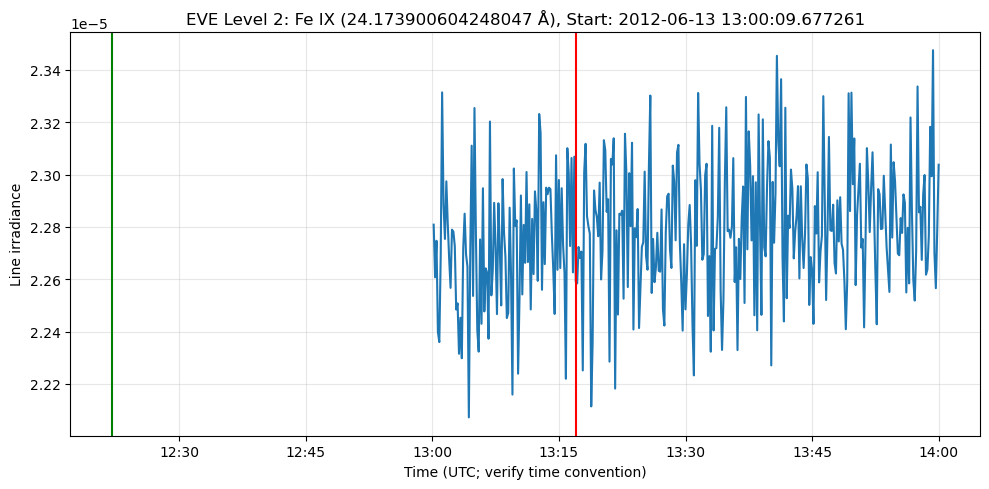

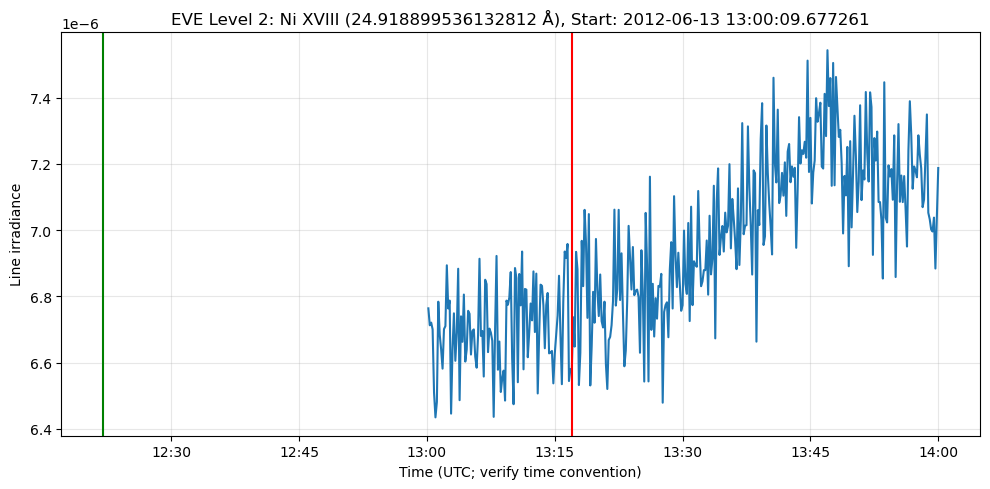

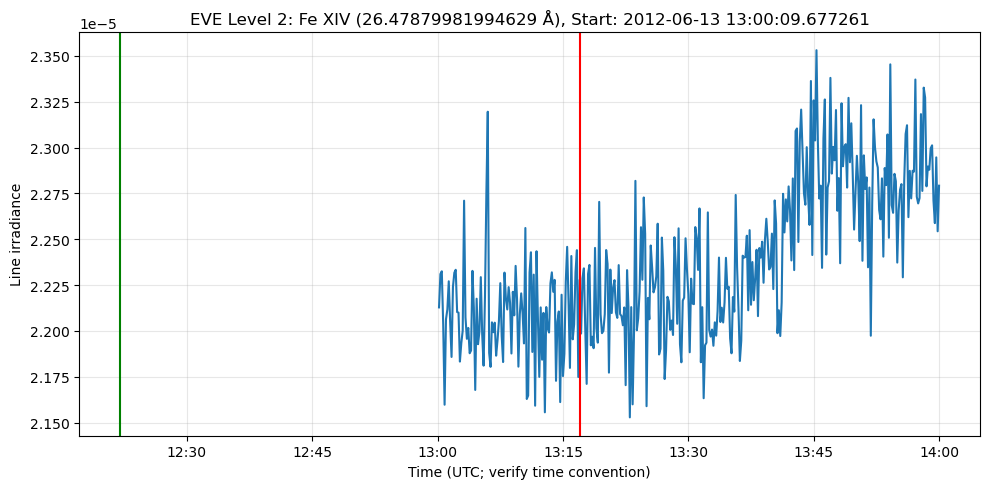

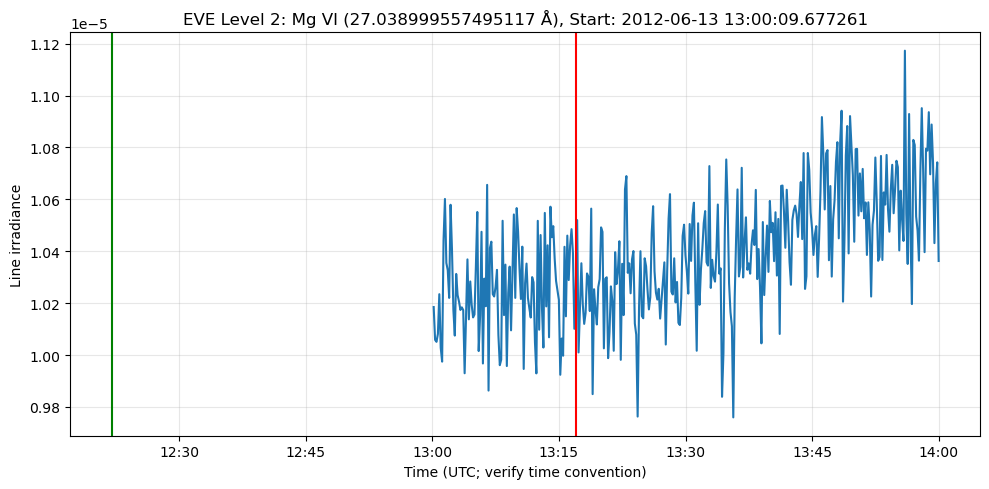

In [7]:

testing=1
plotting=1


if testing==1:    # controles number of files
    arr=range(171,172)
else:
    arr=range(len(evefilename))


#with open('emission_and_flares_data.csv', 'w', newline='') as csvfile:
    #spamwriter = csv.writer(csvfile, delimiter=',', quotechar='|', quoting=csv.QUOTE_MINIMAL)
if 1==1:
    
    if testing==0:
        spamwriter.writerow(['Flare', 'event_starttime', 'event_peaktime','event_endtime',
                            'flare_class','distance from disk','EVE_file','XRS_file','Soft X-Ray','Soft X-ray Background',
                            'Fe XVIII','Fe VIII','Fe XX','Fe IX','Fe X','Fe XI','Fe XII',
                            'Fe XIII','Fe XIV','He II','Fe XV','He II','Fe XVI','Fe XVI',
                            'Mg IX','S XIV','Ne VII','Si XII','Si XII','O III','He I','O IV',
                            'Al XI','He I','Fe XIX','O III','Mg X','Mg X','O V','O II','Fe XX',
                            'Ne VIII','O IV','O II','H I','H I','C III','H I','O VI',
                            'Fe XVIII','Fe XXII','Ni XI','Fe X','Fe XIII','O V','Fe IX',
                            'Fe XIV','Fe XV','O IV','Fe IX','Ni XVIII','Fe XIV','Mg VI',
                            'Fe XX','Ar XVI','S XIV','Ne IV','O III','Fe XX','Ne IV','Al XI',
                            'Ne V','C III','O V','N IV','O IV','Fe XXII','C II','N IV','S VI','O VI',
                            'BG Fe XVIII','BG Fe VIII','BG Fe XX','BG Fe IX','BG Fe X','BG Fe XI','BG Fe XII',
                            'BG Fe XIII','BG Fe XIV','BG He II','BG Fe XV','BG He II','BG Fe XVI','BG Fe XVI',
                            'BG Mg IX','BG S XIV','BG Ne VII','BG Si XII','BG Si XII','BG O III','BG He I','BG O IV',
                            'BG Al XI','BG He I','BG Fe XIX','BG O III','BG Mg X','BG Mg X','BG O V','BG O II','BG Fe XX',
                            'BG Ne VIII','BG O IV','BG O II','BG H I','BG H I','BG C III','BG H I','BG O VI',
                            'BG Fe XVIII','BG Fe XXII','BG Ni XI','BG Fe X','BG Fe XIII','BG O V','BG Fe IX',
                            'BG Fe XIV','BG Fe XV','BG O IV','BG Fe IX','BG Ni XVIII','BG Fe XIV','BG Mg VI',
                            'BG Fe XX','BG Ar XVI','BG S XIV','BG Ne IV','BG O III','BG Fe XX','BG Ne IV','BG Al XI',
                            'BG Ne V','BG C III','BG O V','BG N IV','BG O IV','BG Fe XXII','BG C II','BG N IV','BG S VI','BG O VI'
                             ])

    
    for k in arr:

        
        file = "EVL_L2_files/"+evefilename[k]
        
        with fits.open(file) as hdul:

            
            data = hdul["LinesData"].data
            meta = hdul["LinesMeta"].data
        
            line_irradiance = np.asarray(data["LINE_IRRADIANCE"])
            year_doy = data["YYYYDOY"]
            sod = data["SOD"]
            #for i, line in enumerate(meta):
             #   print(i, line["NAME"], line["WAVE_CENTER"]) ##to see the emission lines
        
        # Convert YYYYDOY and SOD to datetime
        times = []
        for yd, seconds in zip(year_doy, sod):
            year = int(yd) // 1000
            doy = int(yd) % 1000
            dt = datetime(year, 1, 1) + timedelta(
                days=doy - 1, seconds=float(seconds)
            )
            times.append(dt)
    
        
        start = time_add(peak_time[k],-55)
        end = time_add(peak_time[k],60)
            
        mask = [(datetime.strptime(start, "%Y-%m-%d %H:%M:%S.%f") <= t <= datetime.strptime(end, "%Y-%m-%d %H:%M:%S.%f")) for t in times]
            
        filtered_times = [t for t, m in zip(times, mask) if m]
        
            
        print(len(times))
                        
        ######################################################## getting the peak flare flux at event peak time 
        print('--'*100); print('--'*100); print('--'*100); print('--'*100); print('--'*100); print('--'*100)
        print(flare_class[k])
        print(radius[k], 'degrees')
        print(evefilename[k])
         
    
        goes = ts.TimeSeries(xrayfilename[k])
        goes_flare = goes.truncate(start, end)
        # GOES long-wavelength channel: 1–8 Å
        flux = goes_flare.to_dataframe()["xrsb"]
        # Find peak flux and its time
        peak_flux = flux.max()
        soft_xray=peak_flux
        print(f"Peak flux: {peak_flux:.4e} W/m²")
        background_softxray=flux.min()


        # goes graph
        if plotting==1:
            
            df = goes_flare.to_dataframe()
            fig, ax = plt.subplots(figsize=(12, 5))
            ax.plot(df.index, df["xrsb"], color="red", label="GOES 1–8 Å flux")
            #ax.axvline(peak_time[k], color="blue", linestyle="--", label="Event time")
            ax.set_xlabel("Time (UTC)")
            ax.set_ylabel("X-ray flux (W/m²)")
            ax.set_yscale("log")
            plt.show()
        
        emisflx=[] 
        bckgrdflx=[]
        
        for i in range(71):          # max is 71
            # Choose an emission line
            line_index = i

            filtered_values = [v for v, m in zip(line_irradiance[:, line_index], mask) if m]
            
            #print({meta[line_index]['NAME']})
            
            if (int(np.average(filtered_values))<0): #get rid of dead data time sections 
                emisflx.append('Nan')
                bckgrdflx.append('Nan')
                continue
            if (int(np.min(filtered_values))<0): #get rid of data time sections with a secton of it not working 
                emisflx.append('Nan')
                bckgrdflx.append('Nan')
                continue
            
            
            
            emisflx.append(max(filtered_values))     #need to truncate too
            bckgrdflx.append(min(filtered_values))
            
            
            if plotting==1:
                plt.figure(figsize=(10, 5))
                plt.plot(filtered_times, filtered_values)
                plt.xlabel("Time (UTC; verify time convention)")
                #plt.xlim(start, end)
                plt.ylabel("Line irradiance")
                plt.title(
                    f"EVE Level 2: {meta[line_index]['NAME']} "
                    f"({meta[line_index]['WAVE_CENTER']} Å)"
                    f", Start: {times[0]}"
                )
                
                plt.axvline(peak_time[k],color="red")      
                plt.axvline(start,color="green")

                
                plt.gca().xaxis.set_major_formatter(
                    mdates.DateFormatter("%H:%M")
                )
                plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()
                
        if testing==0:
            spamwriter.writerow([k, start_times[k], peak_time[k],end_times[k],flare_class[k],radius[k],evefilename[k],xrayfilename[k],soft_xray, background_softxray,
                                emisflx[0],emisflx[1],emisflx[2],emisflx[3],emisflx[4],emisflx[5],emisflx[6],emisflx[7],emisflx[8],emisflx[9],
                                emisflx[10],emisflx[11],emisflx[12],emisflx[13],emisflx[14],emisflx[15],emisflx[16],emisflx[17],emisflx[18],
                                emisflx[19],emisflx[20],emisflx[21],emisflx[22],emisflx[23],emisflx[24],emisflx[25],emisflx[26],emisflx[27],
                                emisflx[28],emisflx[29],emisflx[30],emisflx[31],emisflx[32],emisflx[33],emisflx[34],emisflx[35],emisflx[36],
                                emisflx[37],emisflx[38],emisflx[39],emisflx[40],emisflx[41],emisflx[42],emisflx[43],emisflx[44],emisflx[45],
                                emisflx[46],emisflx[47],emisflx[48],emisflx[49],emisflx[50],emisflx[51],emisflx[52],emisflx[53],emisflx[54],
                                emisflx[55],emisflx[56],emisflx[57],emisflx[58],emisflx[59],emisflx[60],emisflx[61],emisflx[62],emisflx[63],
                                emisflx[64],emisflx[65],emisflx[66],emisflx[67],emisflx[68],emisflx[69],emisflx[70],
                                bckgrdflx[0],bckgrdflx[1],bckgrdflx[2],bckgrdflx[3],bckgrdflx[4],bckgrdflx[5],bckgrdflx[6],bckgrdflx[7],bckgrdflx[8],bckgrdflx[9],
                                bckgrdflx[10],bckgrdflx[11],bckgrdflx[12],bckgrdflx[13],bckgrdflx[14],bckgrdflx[15],bckgrdflx[16],bckgrdflx[17],bckgrdflx[18],
                                bckgrdflx[19],bckgrdflx[20],bckgrdflx[21],bckgrdflx[22],bckgrdflx[23],bckgrdflx[24],bckgrdflx[25],bckgrdflx[26],bckgrdflx[27],
                                bckgrdflx[28],bckgrdflx[29],bckgrdflx[30],bckgrdflx[31],bckgrdflx[32],bckgrdflx[33],bckgrdflx[34],bckgrdflx[35],bckgrdflx[36],
                                bckgrdflx[37],bckgrdflx[38],bckgrdflx[39],bckgrdflx[40],bckgrdflx[41],bckgrdflx[42],bckgrdflx[43],bckgrdflx[44],bckgrdflx[45],
                                bckgrdflx[46],bckgrdflx[47],bckgrdflx[48],bckgrdflx[49],bckgrdflx[50],bckgrdflx[51],bckgrdflx[52],bckgrdflx[53],bckgrdflx[54],
                                bckgrdflx[55],bckgrdflx[56],bckgrdflx[57],bckgrdflx[58],bckgrdflx[59],bckgrdflx[60],bckgrdflx[61],bckgrdflx[62],bckgrdflx[63],
                                bckgrdflx[64],bckgrdflx[65],bckgrdflx[66],bckgrdflx[67],bckgrdflx[68],bckgrdflx[69],bckgrdflx[70]
                                ])
            

# Temperature of each Wavelengeth 

In [24]:
with fits.open("EVL_L2_files/"+evefilename[0]) as hdul:

    hdu = hdul["LinesMeta"]
    print('Temp(K)', hdu.columns.names[3], hdu.columns.names[4], hdu.columns.names[5], hdu.columns.names[6])
    #if hdu.data is not None:
      #   print(hdu.data)

    for i in range(len(hdu.data[i])):
        print(round(10**(hdu.data[i][3]),3),hdu.data[i][3],hdu.data[i][4],hdu.data[i][5],hdu.data[i][6])

Temp(K) LOGT NAME TYPE BLENDS
6.4565415e+06 6.81 Fe XVIII F 
371535.38 5.57 Fe VIII K Fe VIII
9.332538e+06 6.97 Fe XX N Fe XXIII
645654.1 5.81 Fe IX Ar 
977236.7 5.99 Fe X Cl Fe VII
1.174898e+06 6.07 Fe XI S Fe X, Fe VII
1.3489632e+06 6.13 Fe XII P 


# Part 3
## Binning flares by location to ratio of peak soft x-ray to specific emission

3. There is also a flare-specific background
This may actually be more useful if your objective is to detect individual enhancements.

NOAA provides an XRS Flare Summary (flsum) product.

It includes:
- Flare start time.
- Flare peak time.
- Flare end time.
- Peak irradiance.
- Background irradiance associated with the flare.
- Integrated irradiance.
The background is estimated from the pre-flare measurements, using an exponential fit to the initial rise when appropriate. NOAA notes that this can be more suitable than a daily background for individual flare analysis. 
data.ngdc.noaa.gov+1

Your research objective	Recommended product
Background variation over days/months	bkd1d

In [9]:
df = pd.read_csv('emission_and_flares_data.csv')

data_lists = {}

for column in df.columns:
    data_lists[column] = df[column].tolist()

titles=list(data_lists.keys())


In [20]:
from scipy import stats

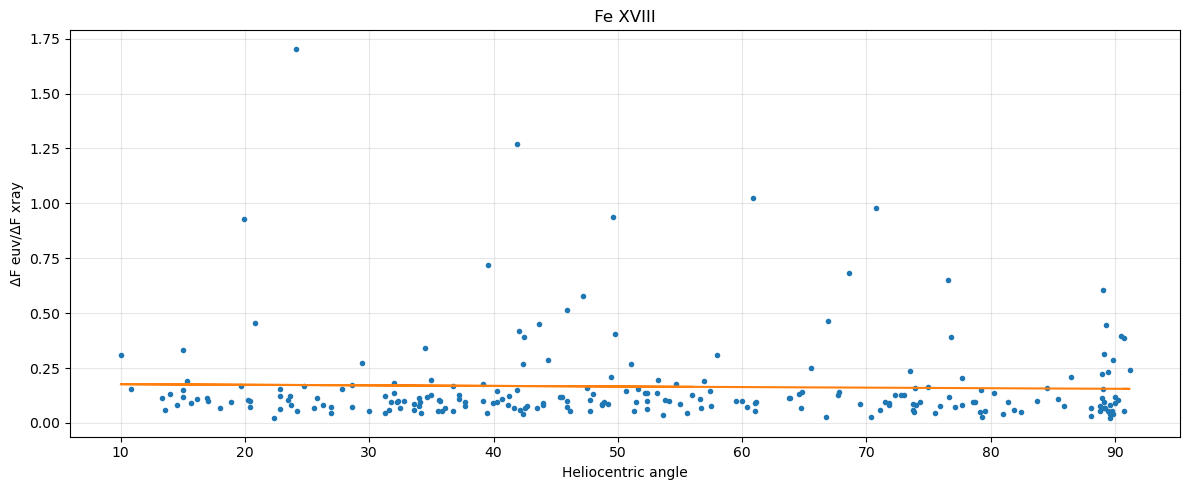

slope= -0.000262
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


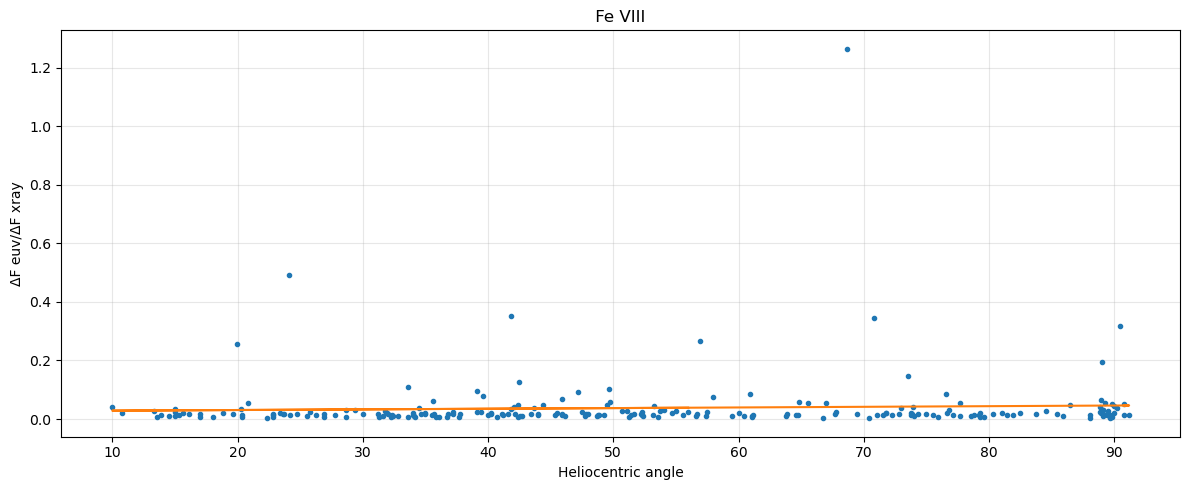

slope= 0.000219
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


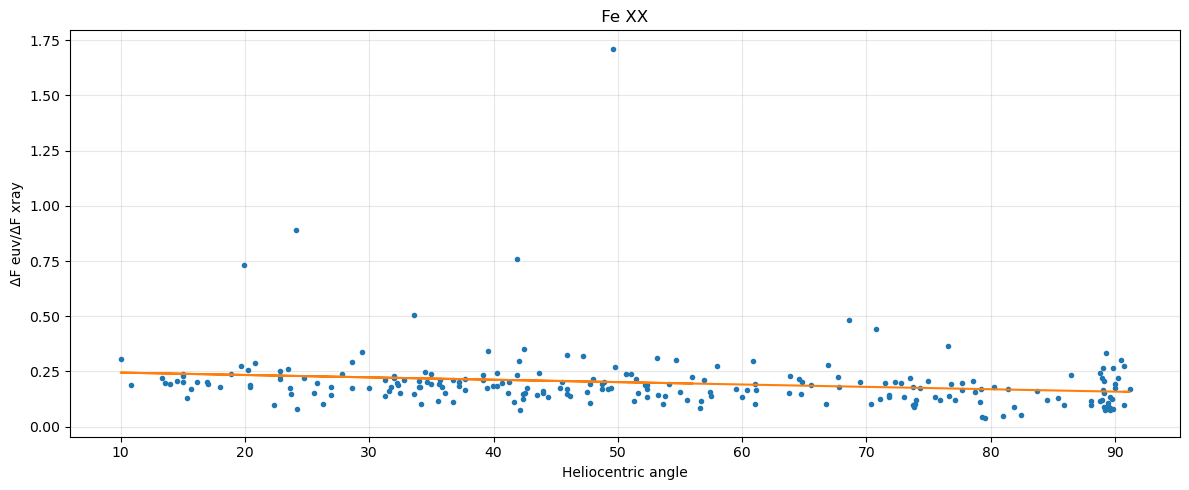

slope= -0.001077
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


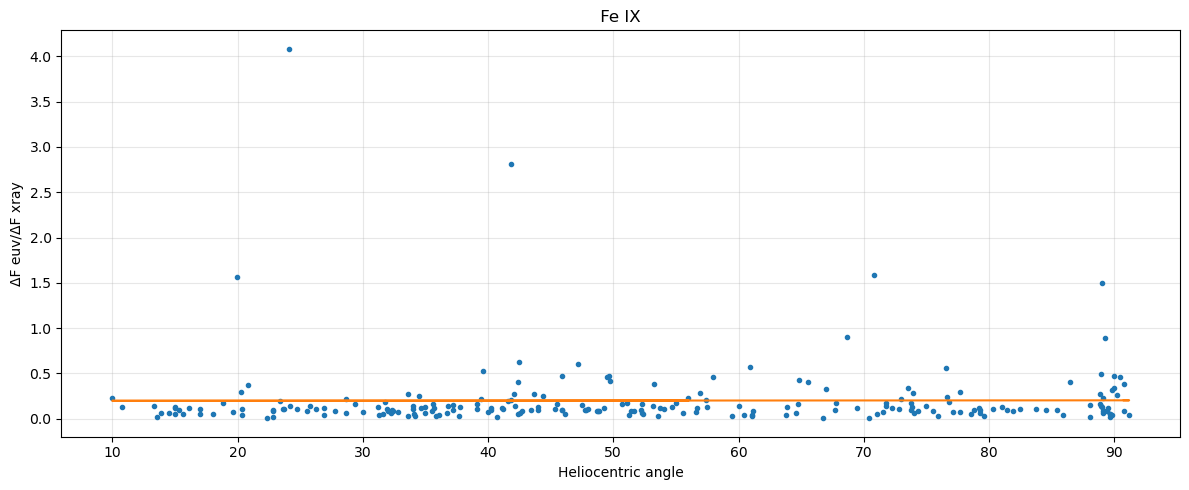

slope= 6.7e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


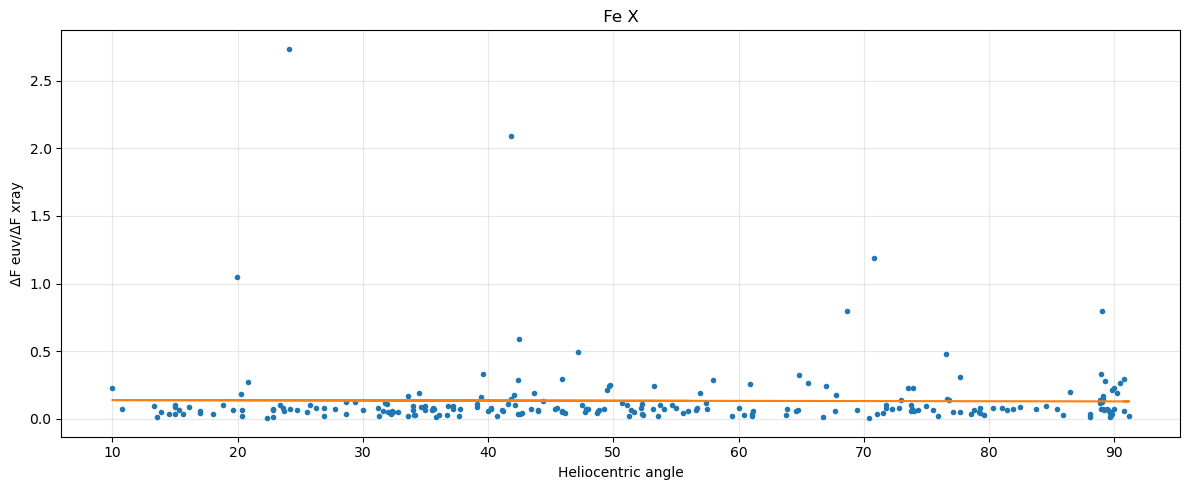

slope= -0.00012
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


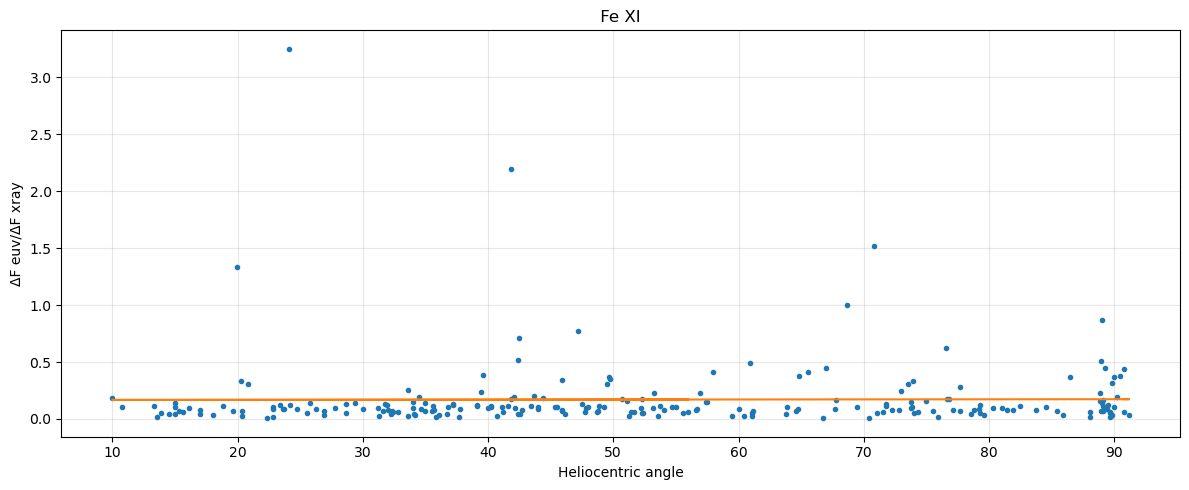

slope= 8e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


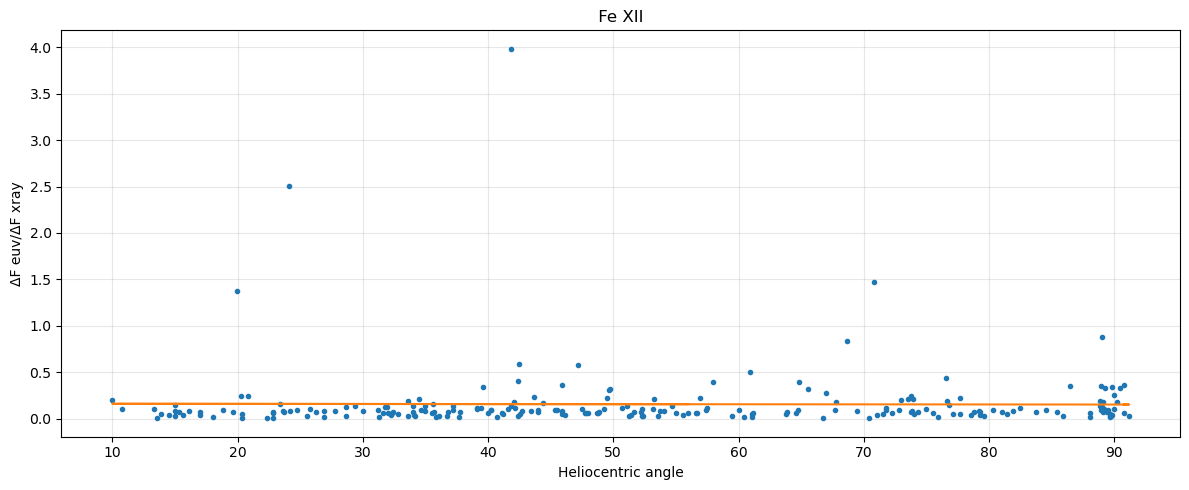

slope= -0.0001
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


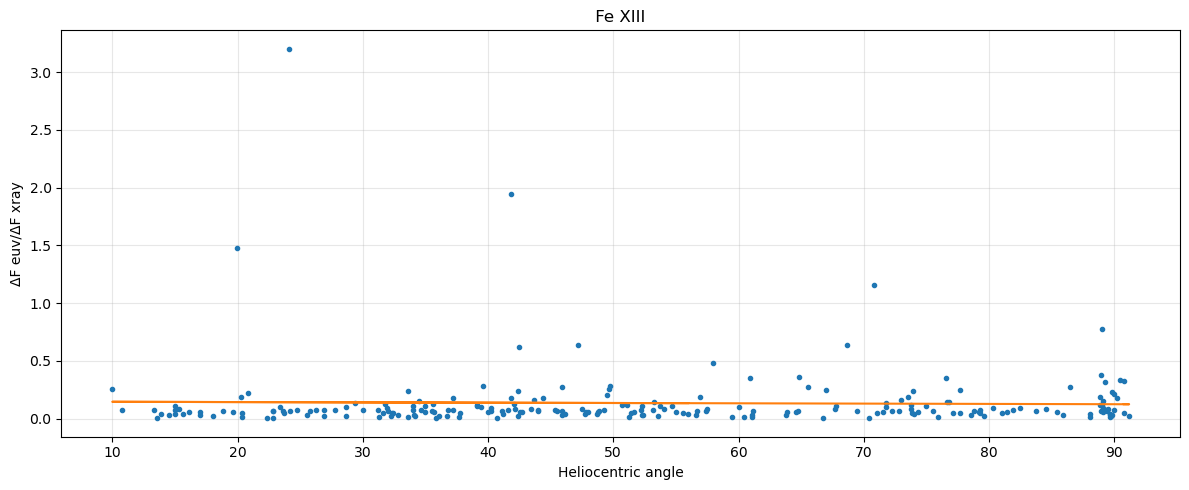

slope= -0.000264
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


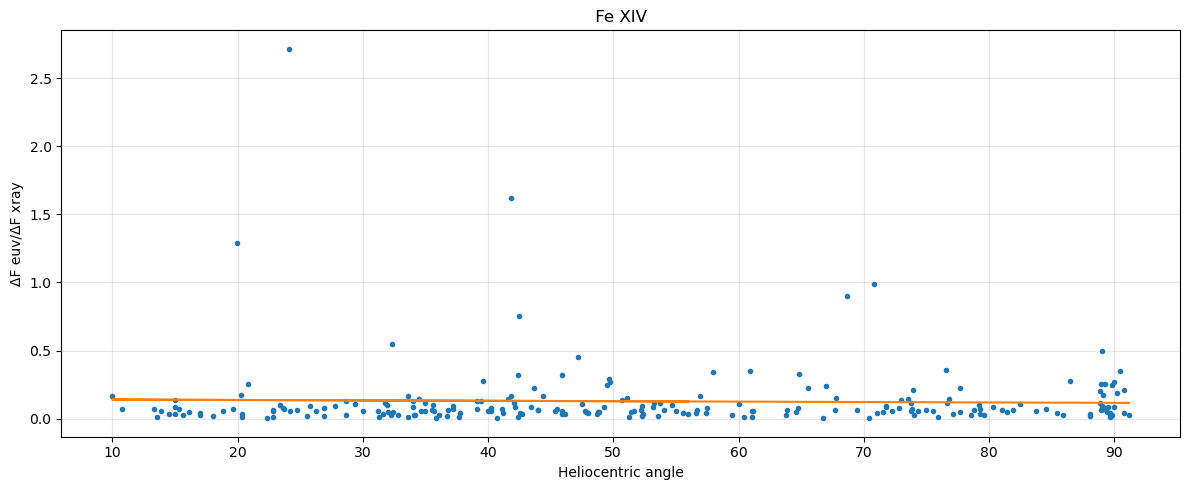

slope= -0.000302
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


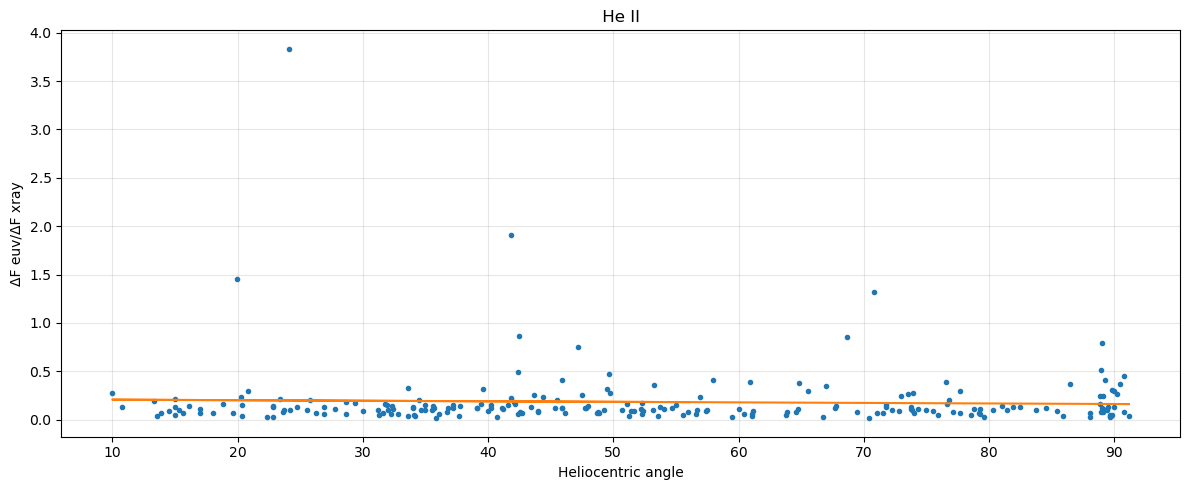

slope= -0.00056
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


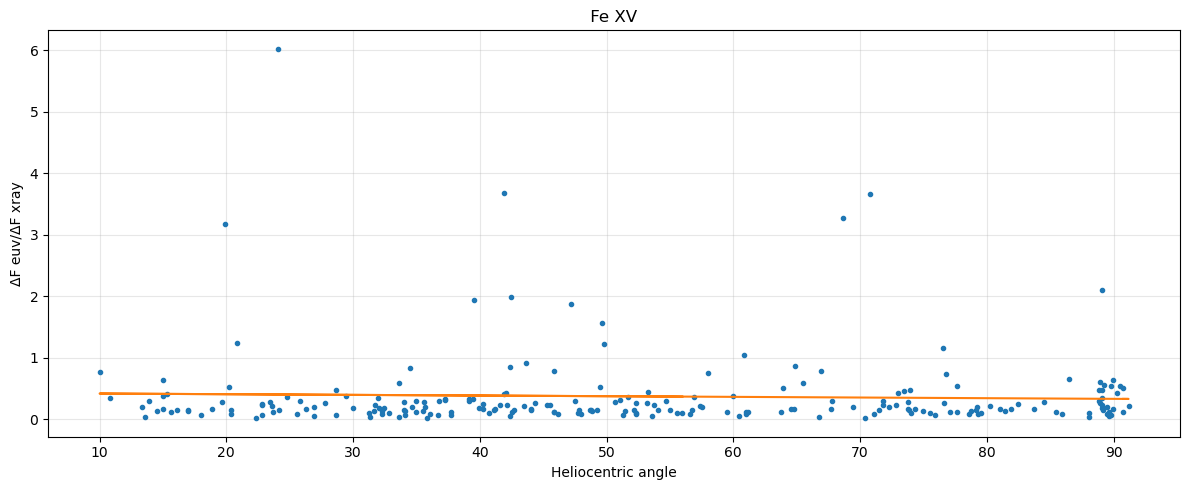

slope= -0.001077
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


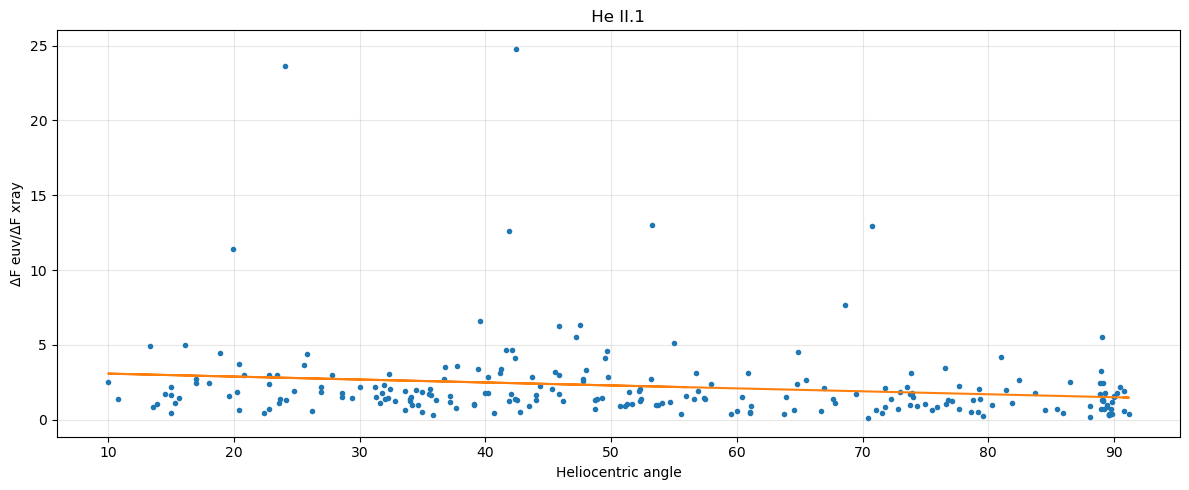

slope= -0.01973
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


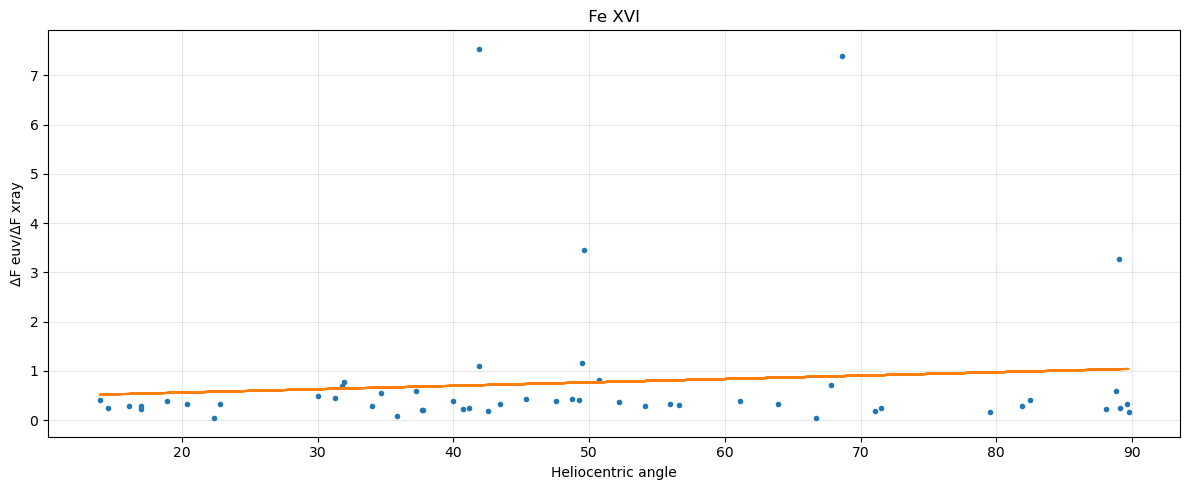

slope= 0.006892
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


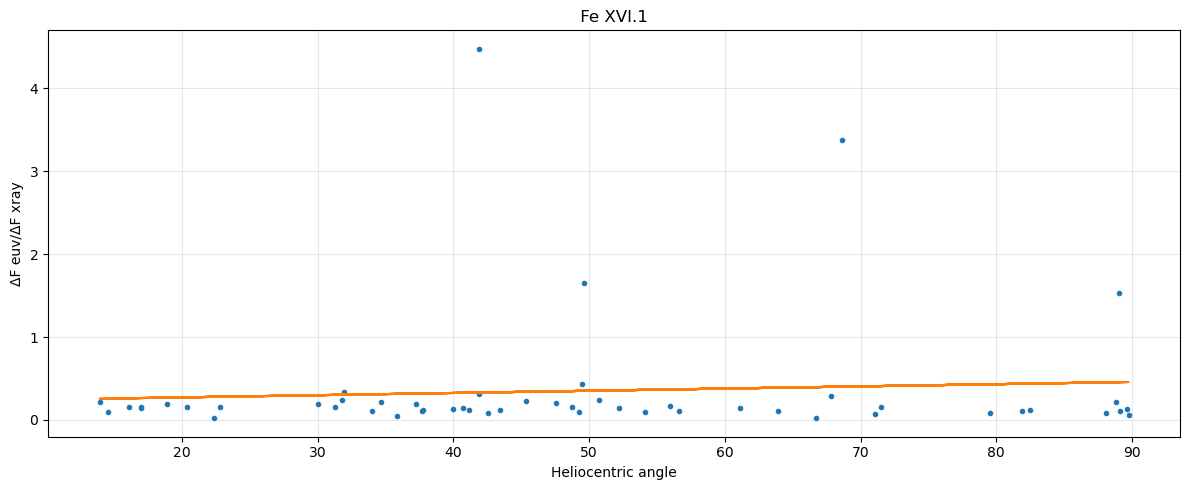

slope= 0.002653
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


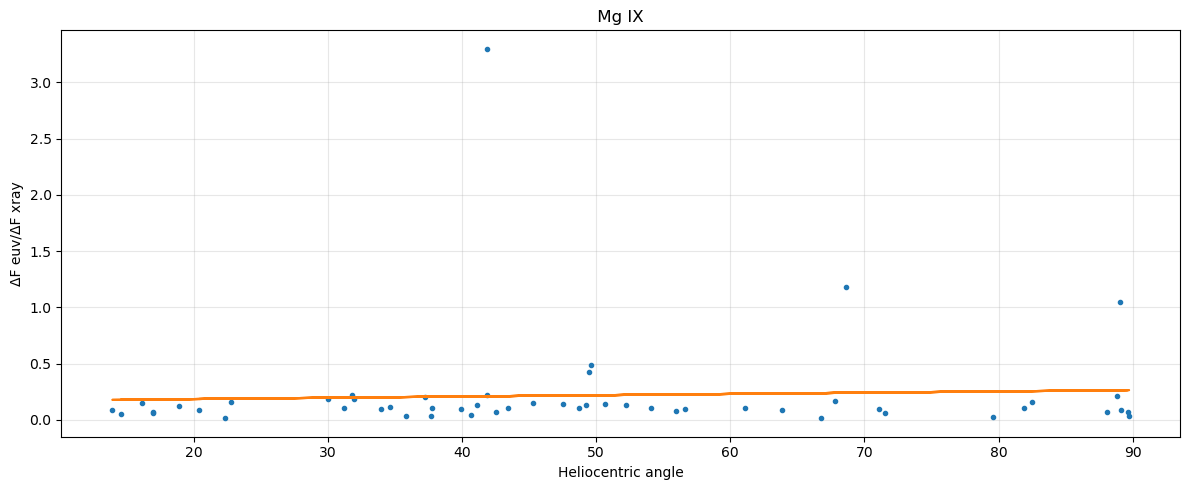

slope= 0.001132
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


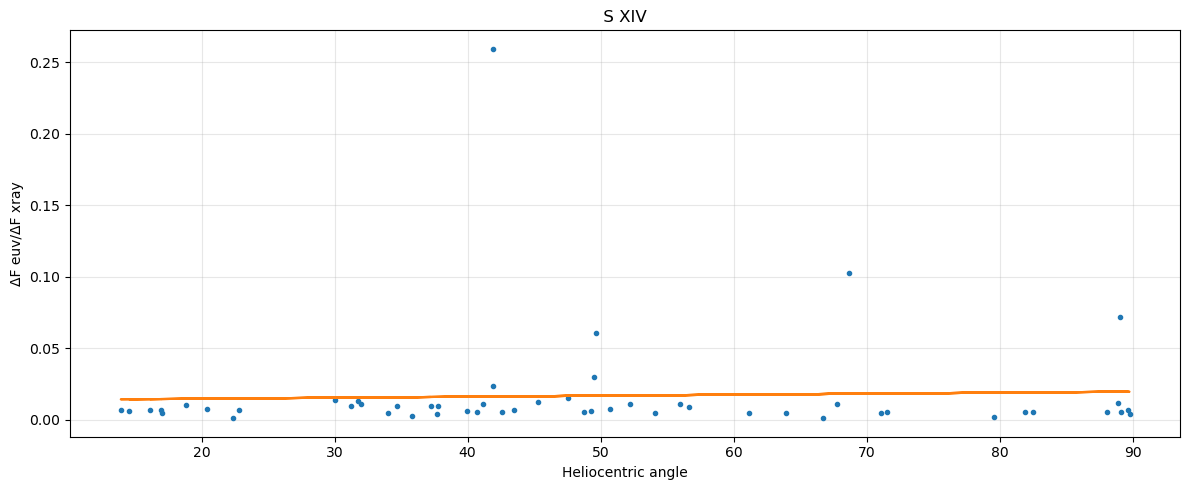

slope= 7.1e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


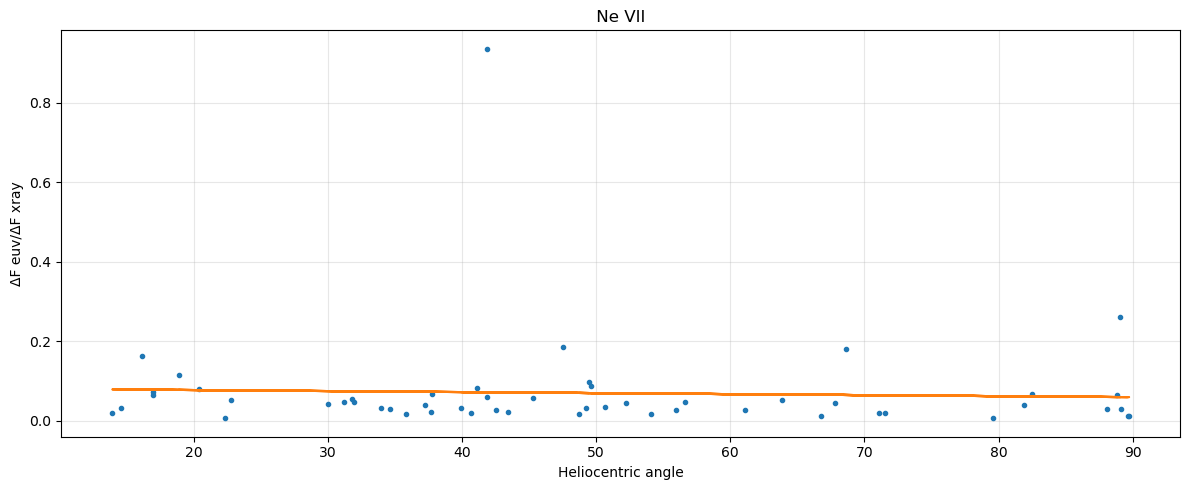

slope= -0.000256
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


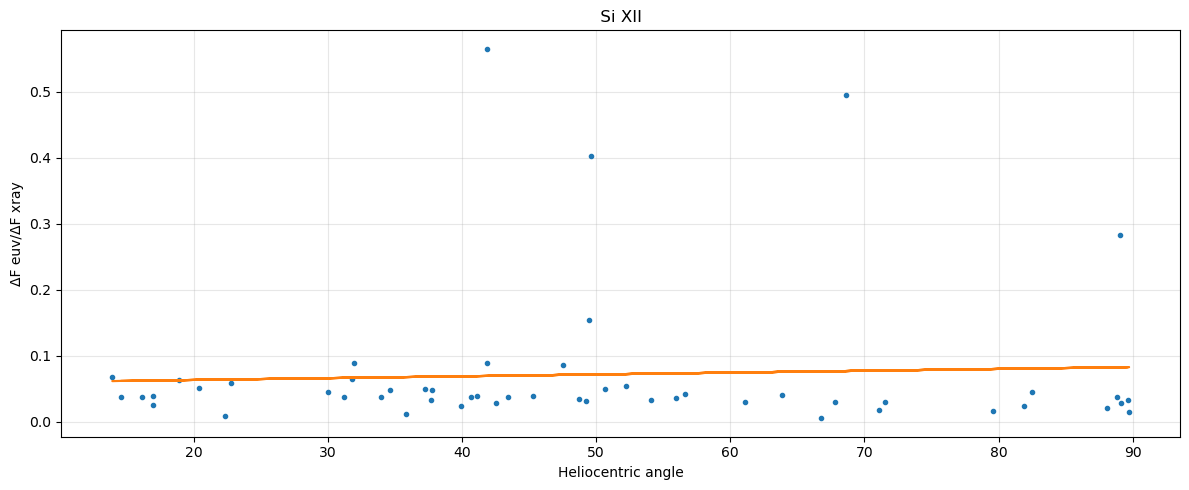

slope= 0.000278
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


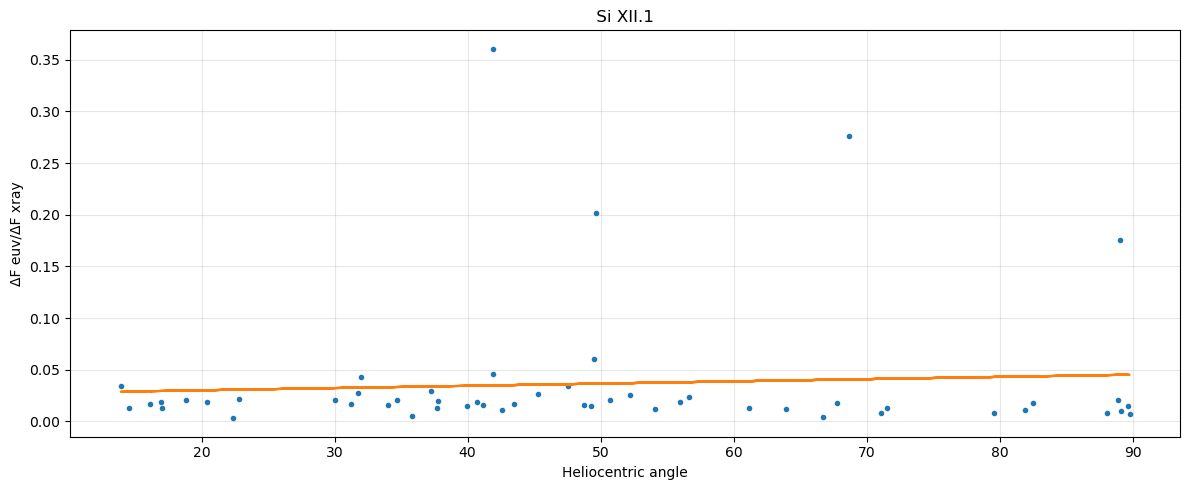

slope= 0.000216
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


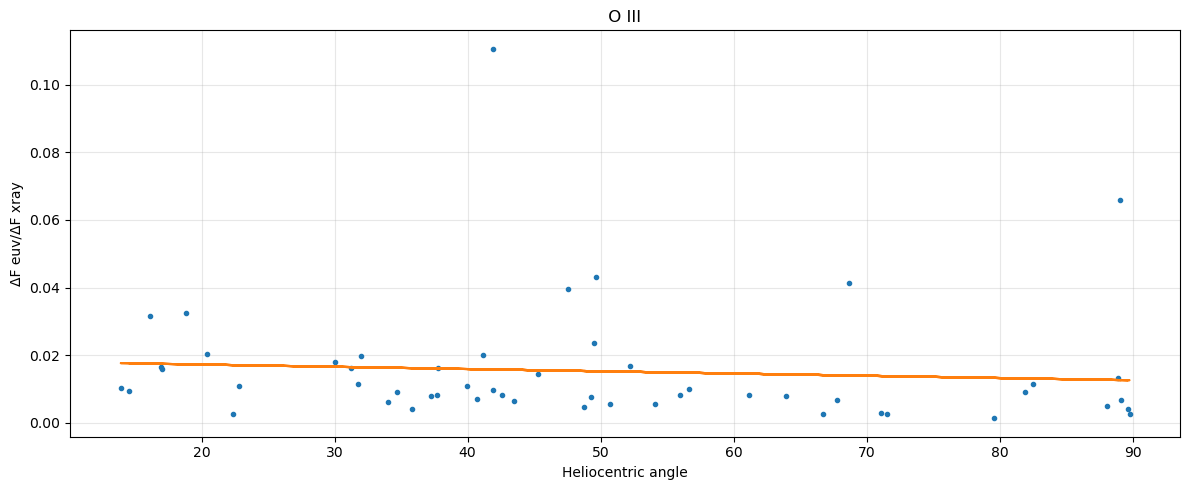

slope= -6.7e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


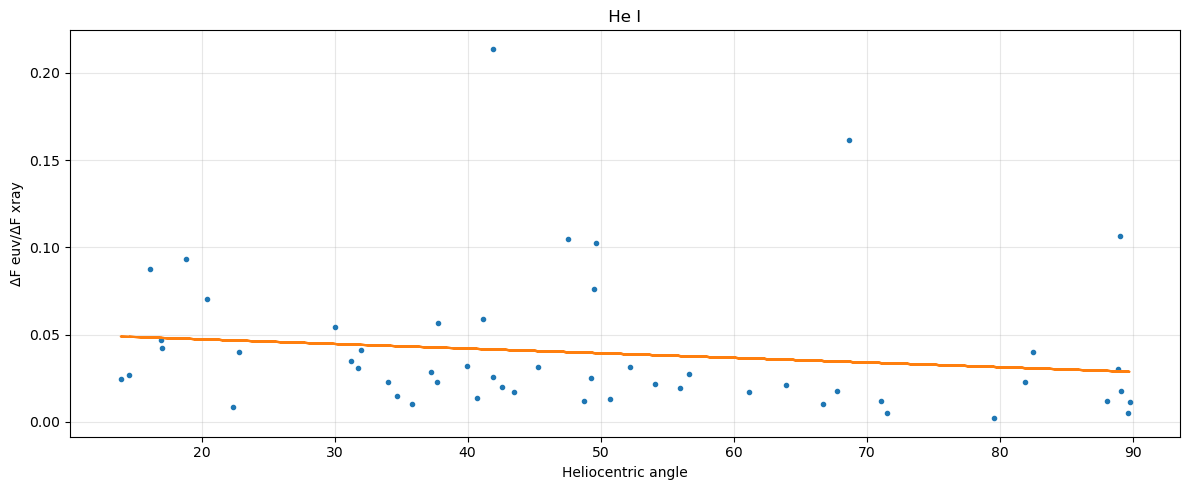

slope= -0.000266
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


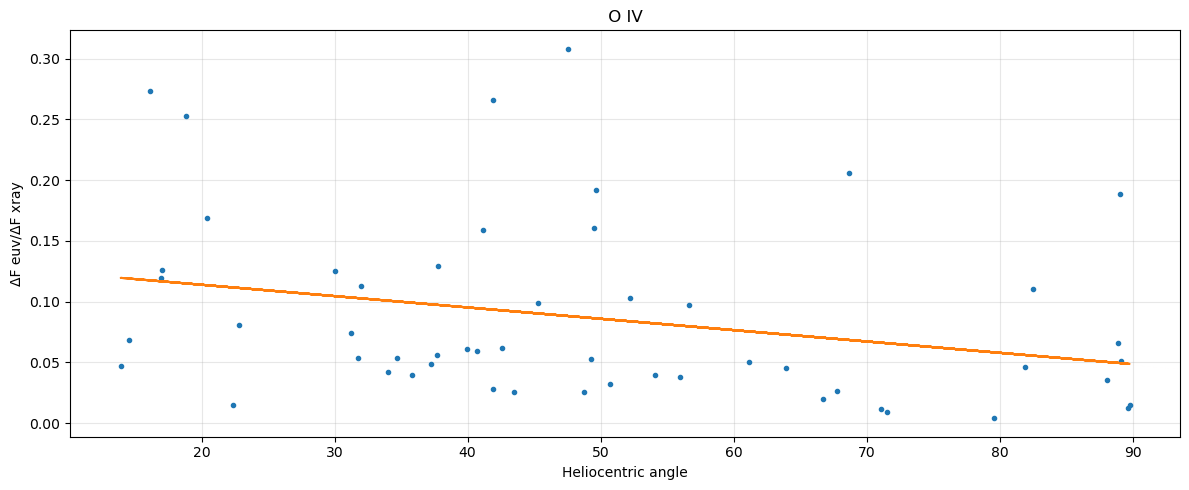

slope= -0.000934
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


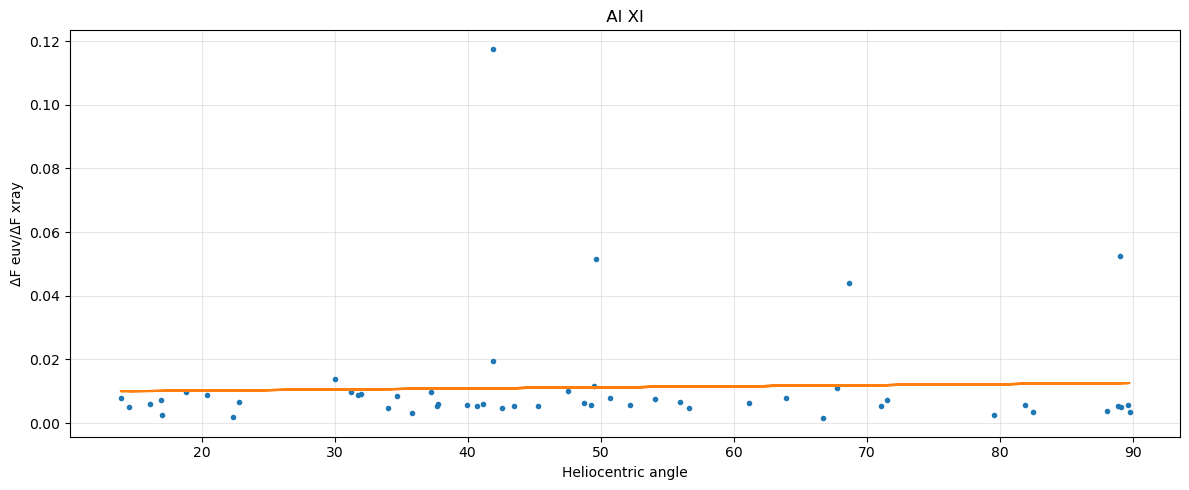

slope= 3.4e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


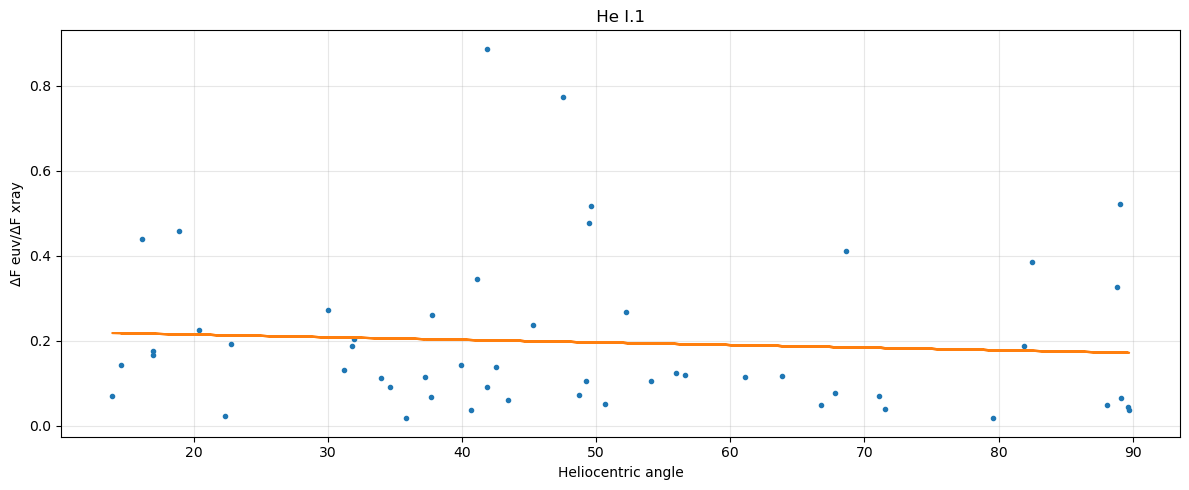

slope= -0.000613
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


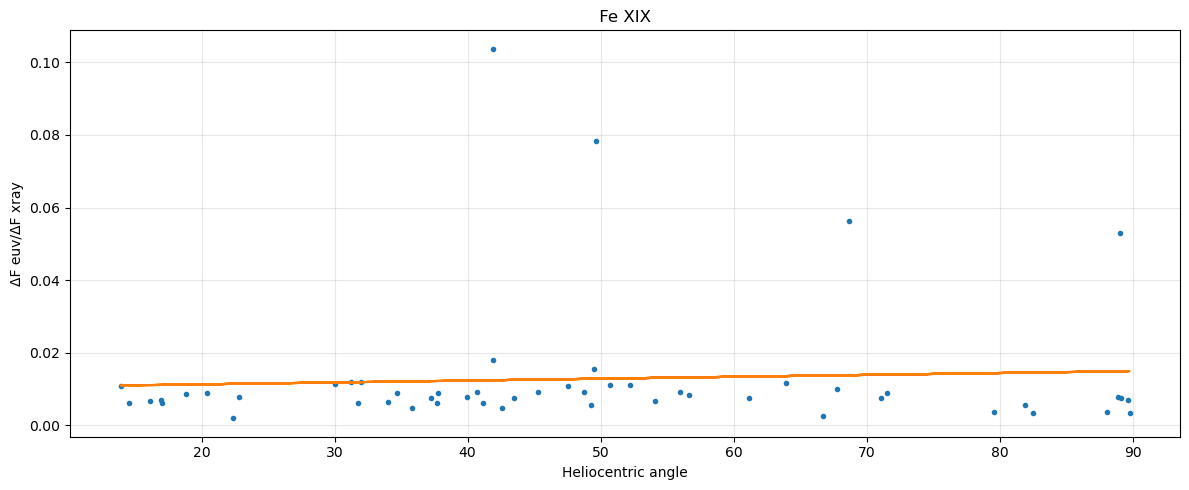

slope= 5.2e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


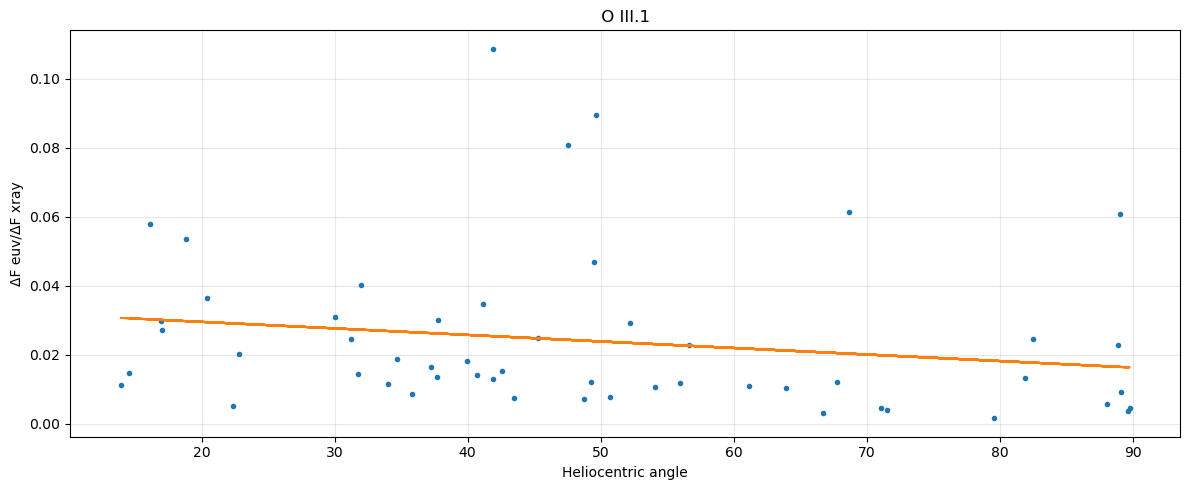

slope= -0.000189
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


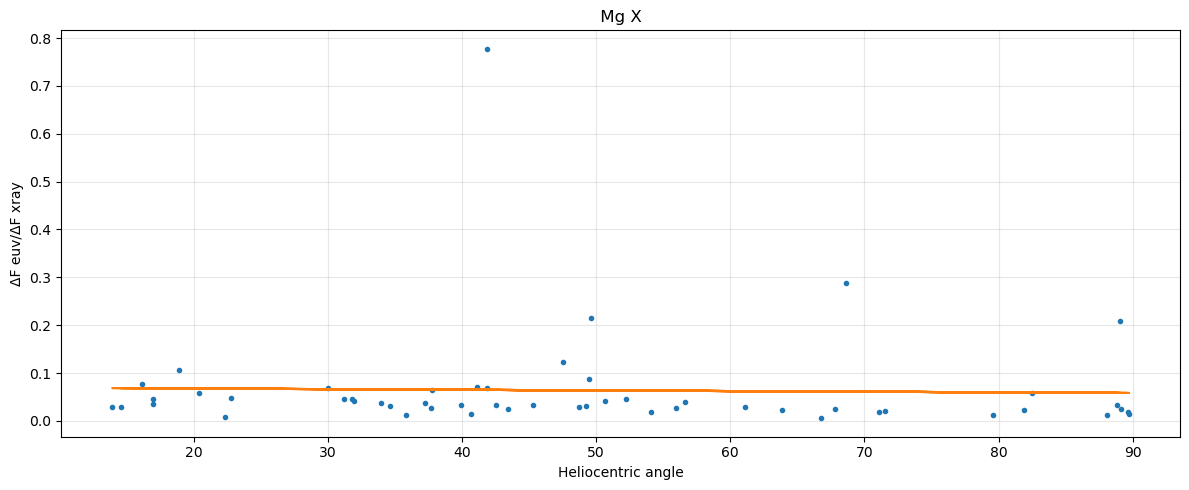

slope= -0.000134
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


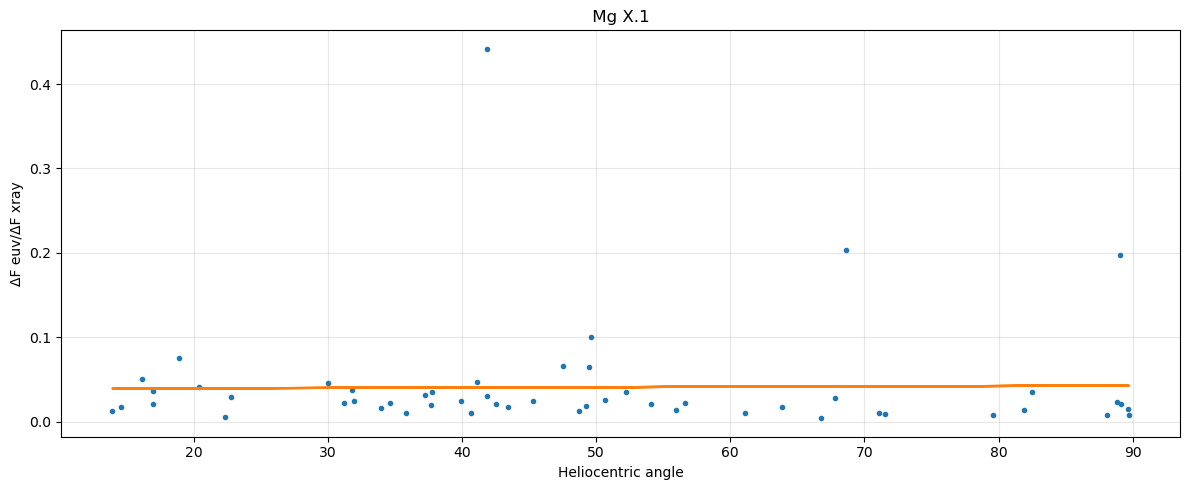

slope= 4.6e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


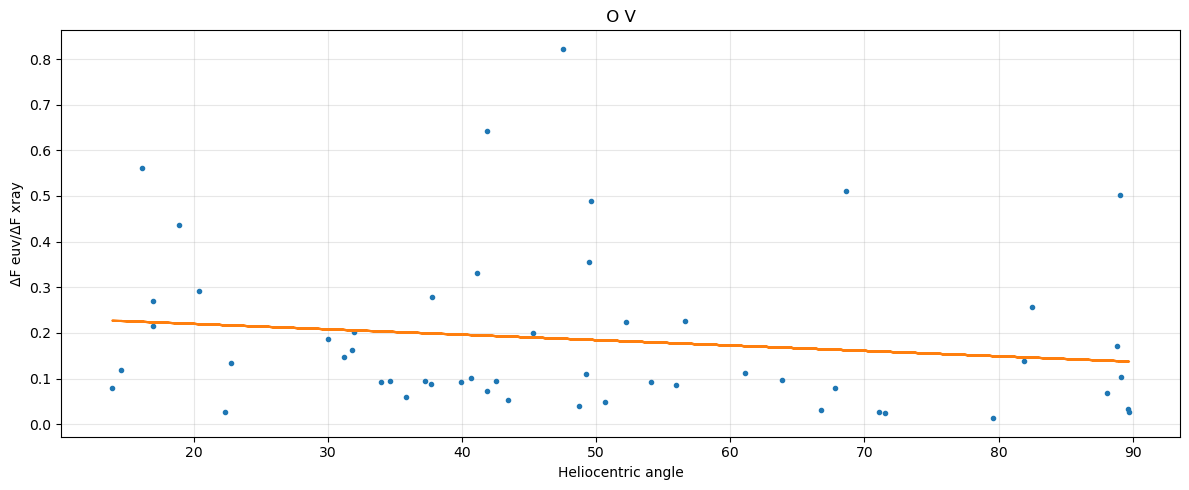

slope= -0.001183
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


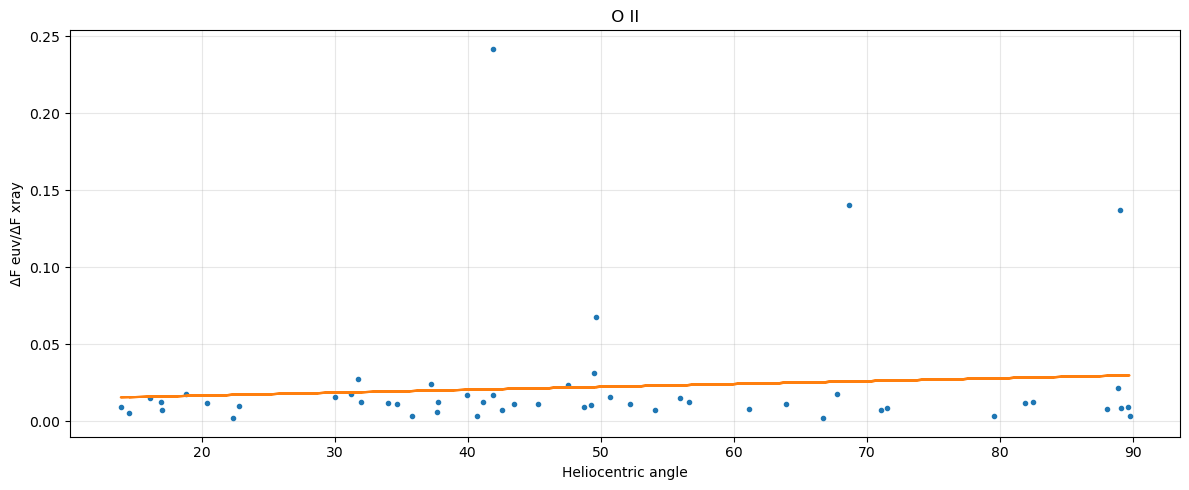

slope= 0.000188
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


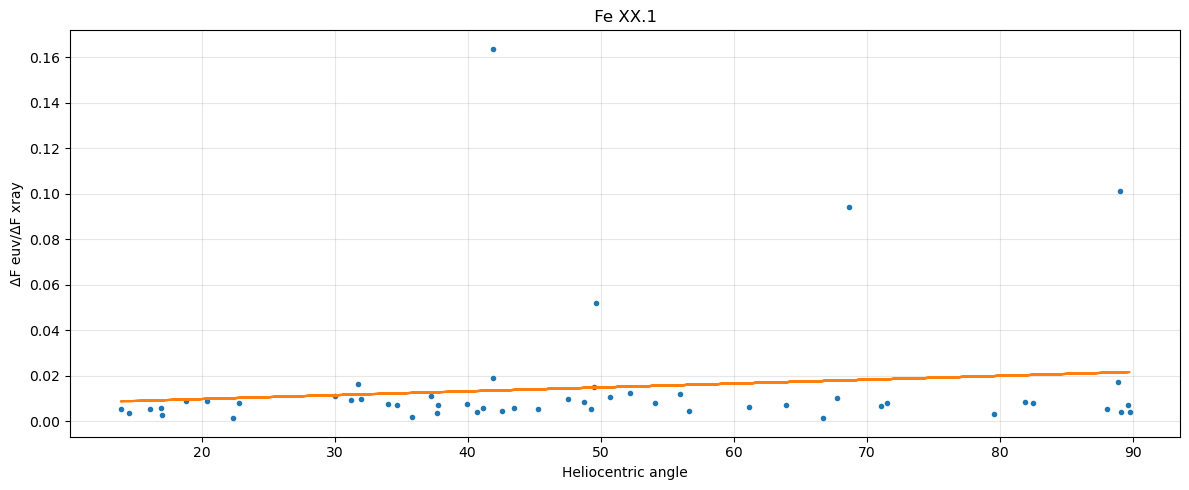

slope= 0.00017
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


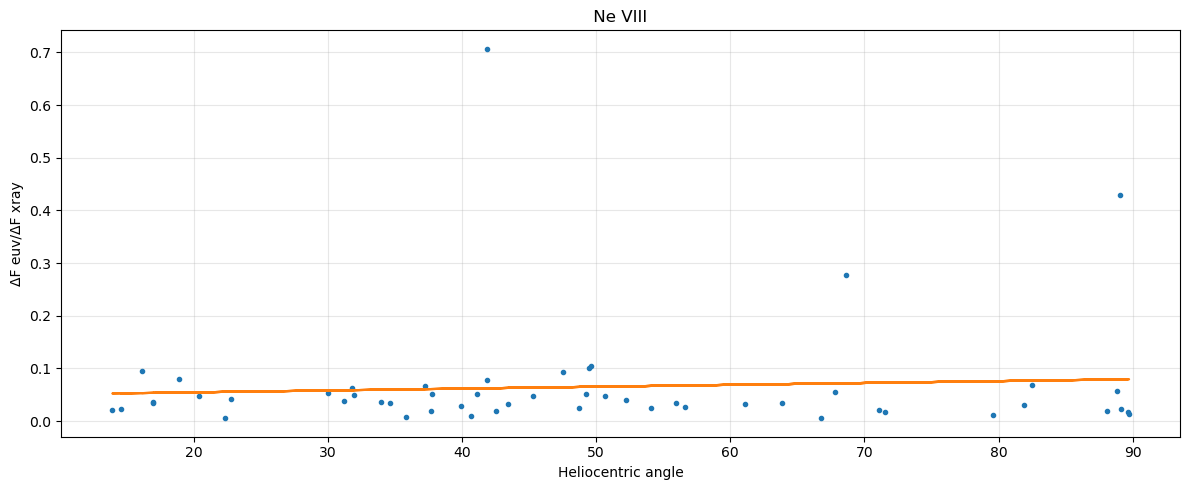

slope= 0.000355
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


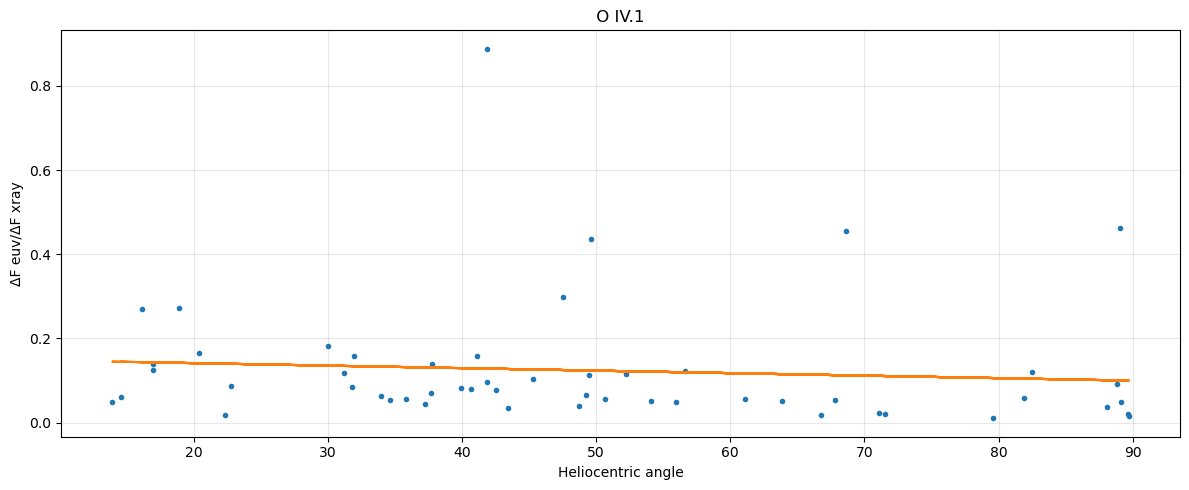

slope= -0.000595
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


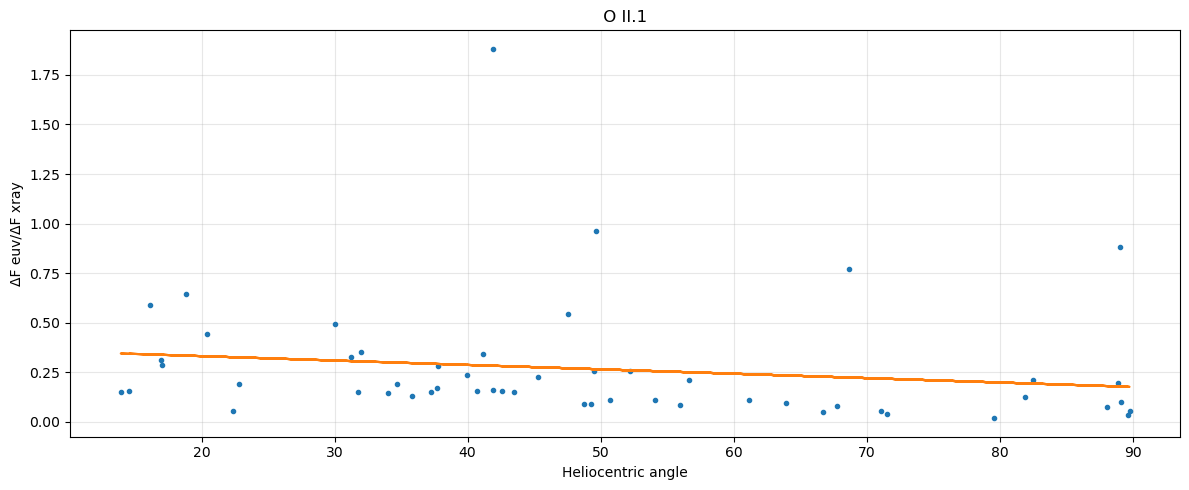

slope= -0.002217
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


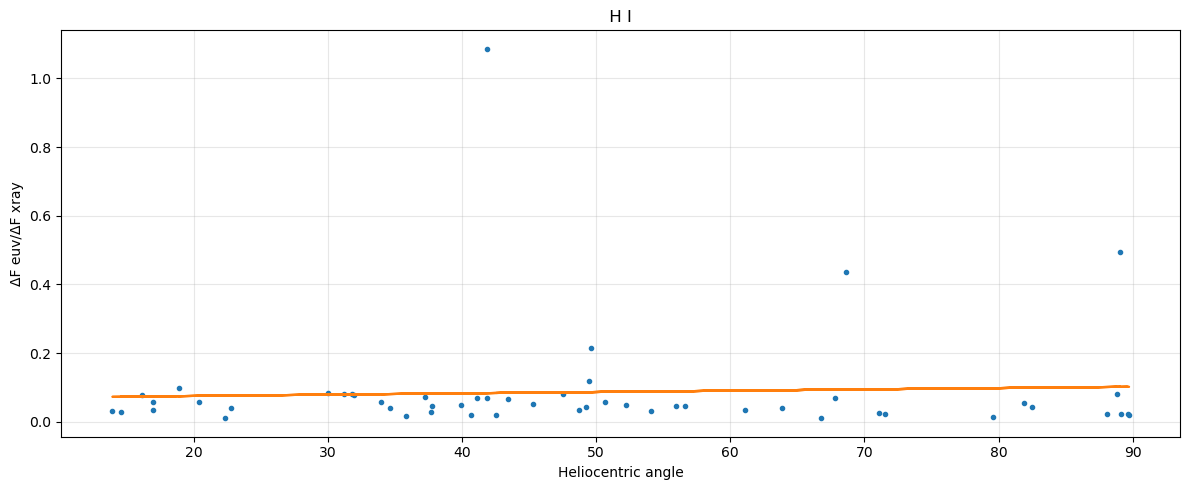

slope= 0.000383
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


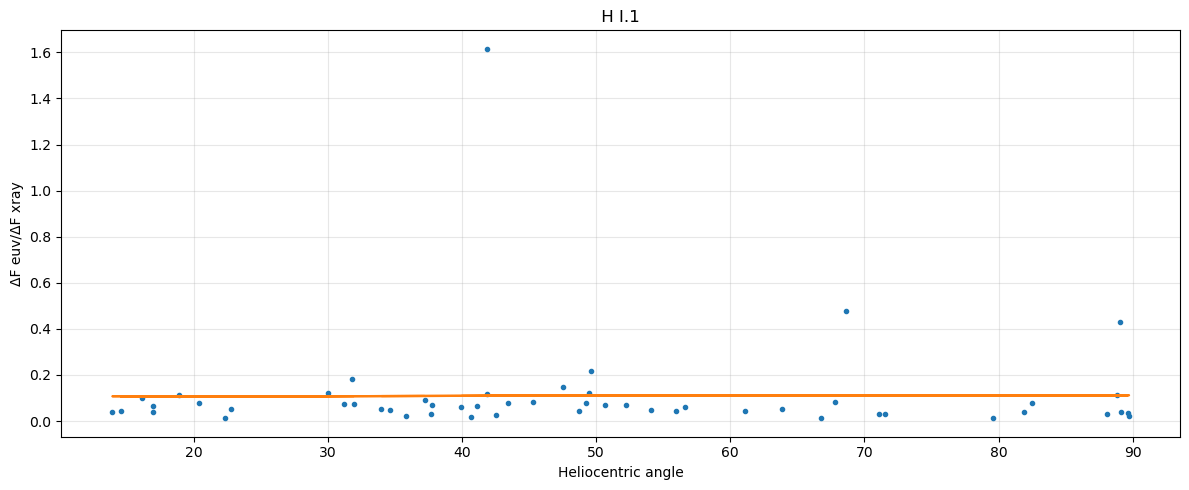

slope= 5.9e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


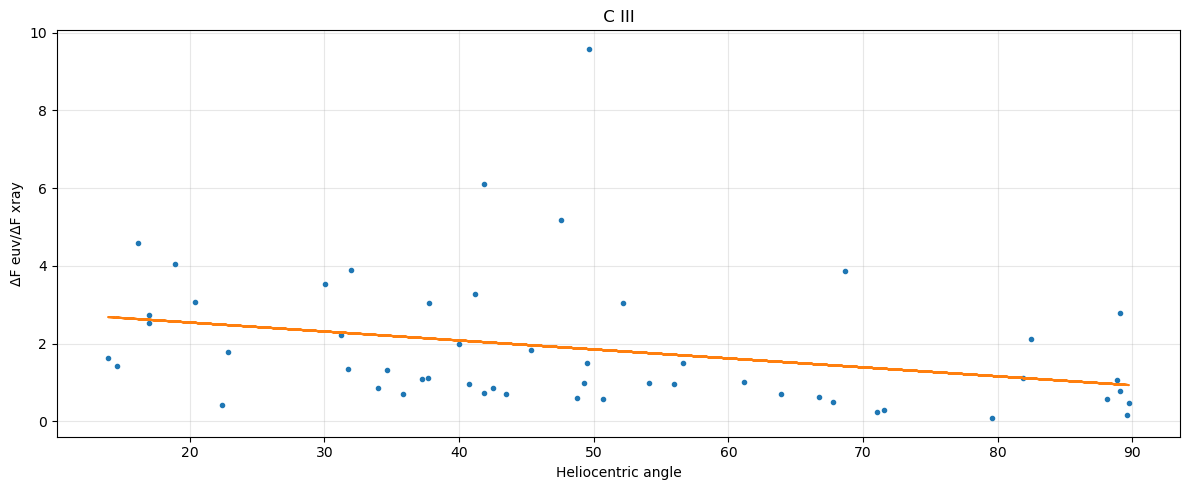

slope= -0.023075
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


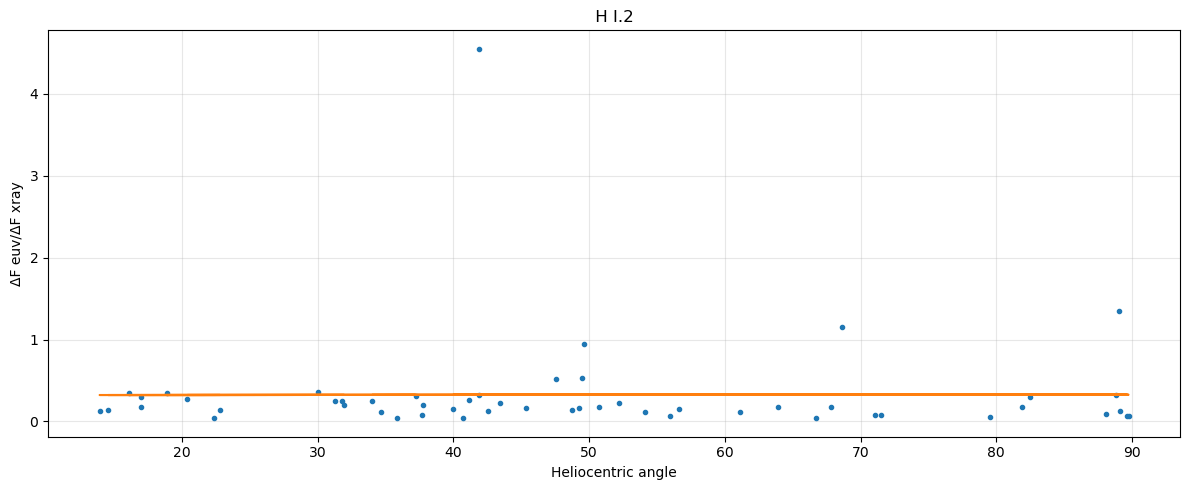

slope= 5.2e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


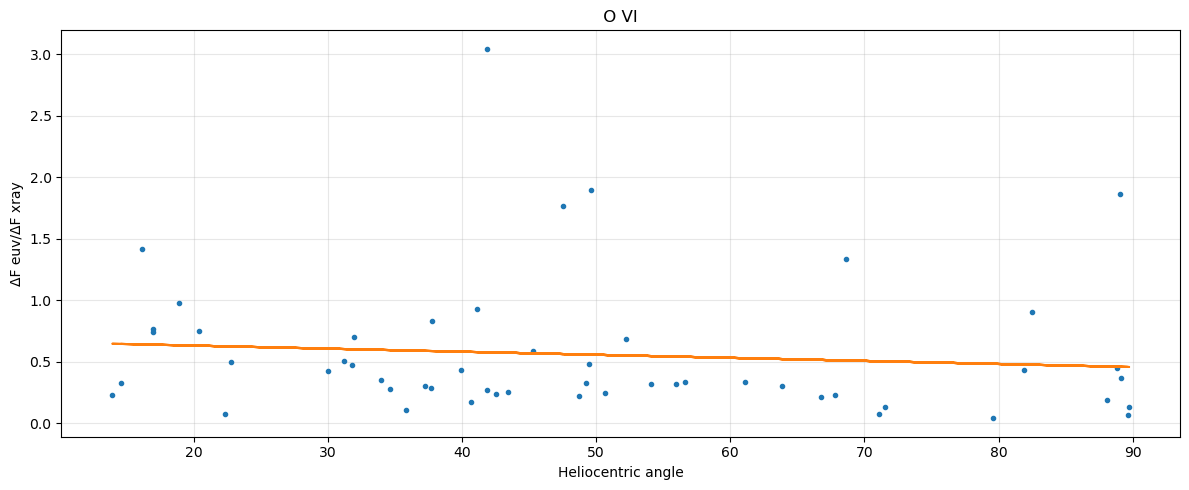

slope= -0.002493
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


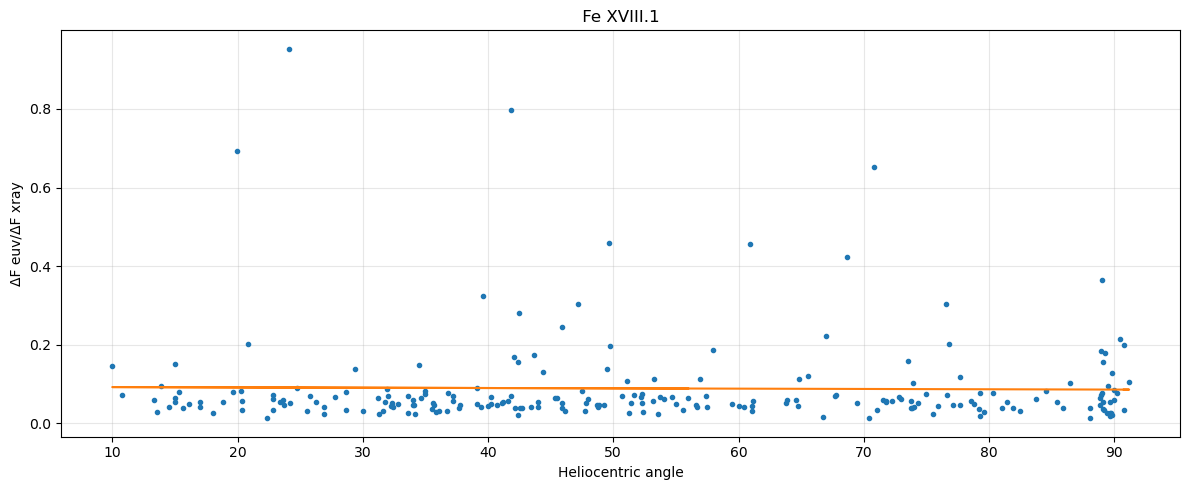

slope= -7.9e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


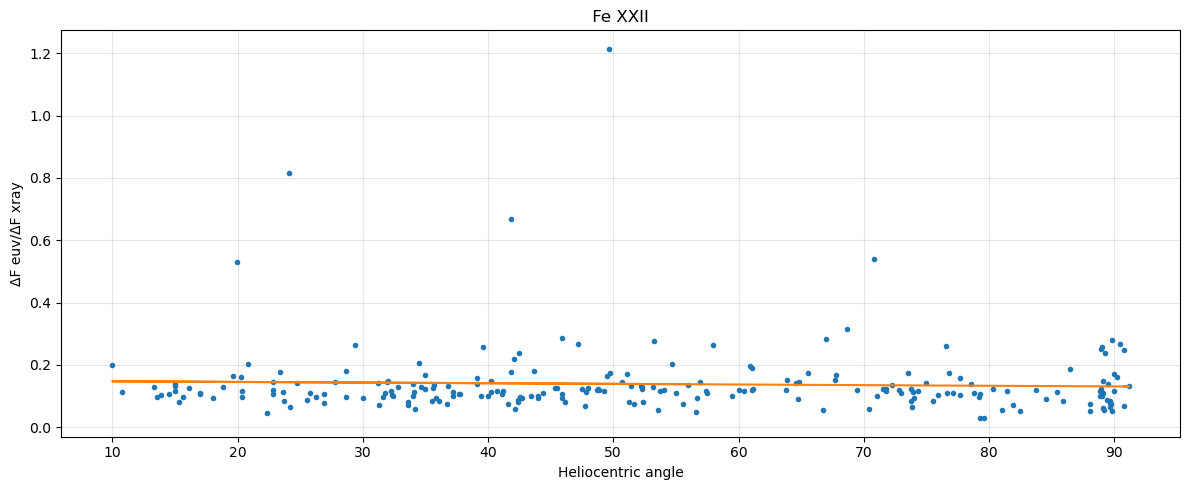

slope= -0.000205
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


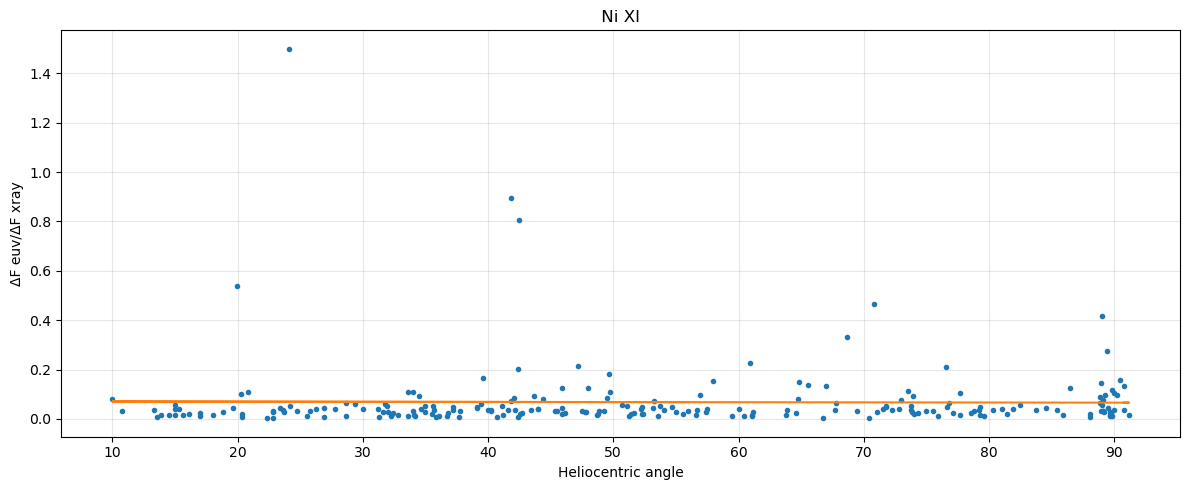

slope= -5.7e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


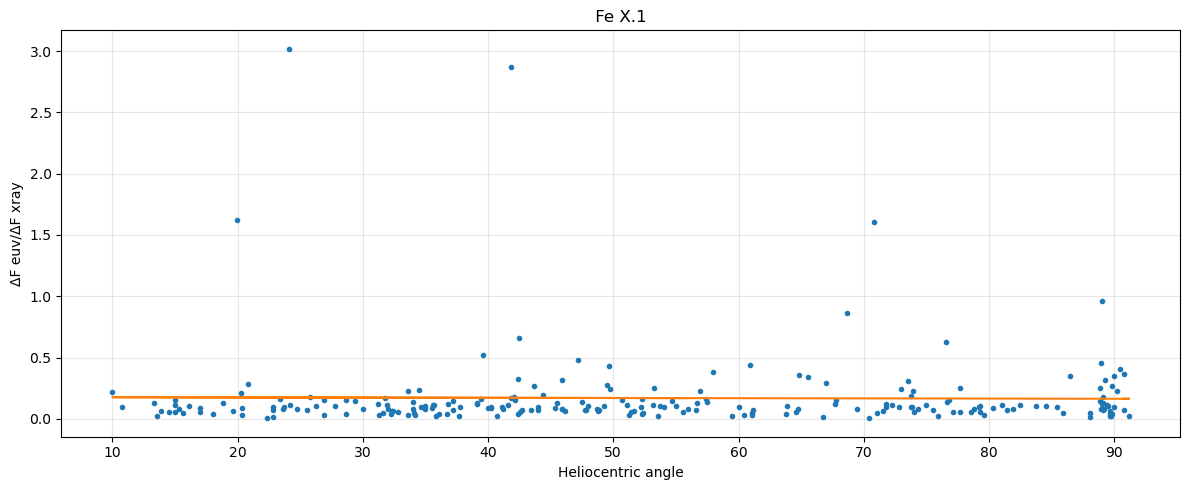

slope= -0.000156
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


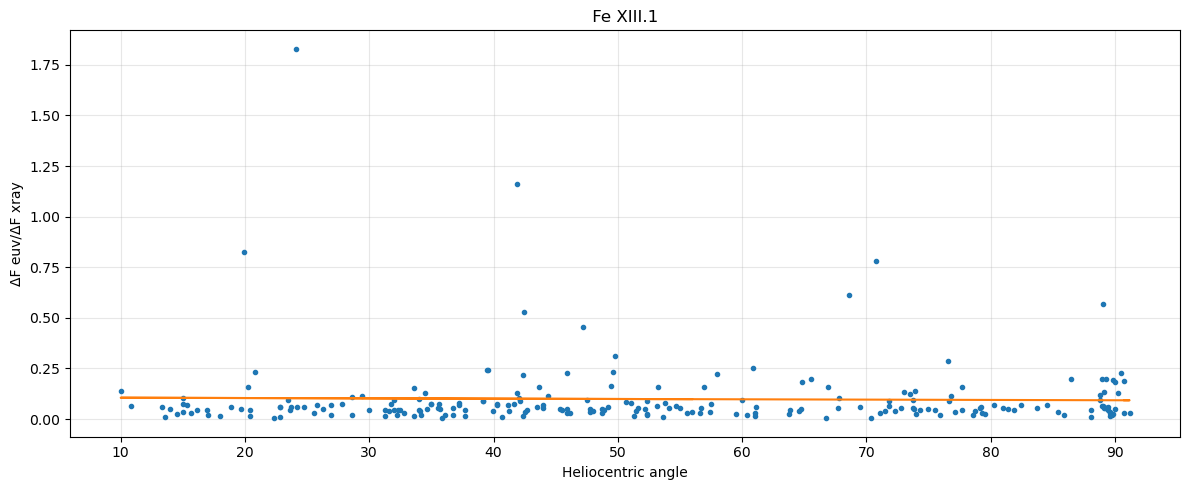

slope= -0.000157
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


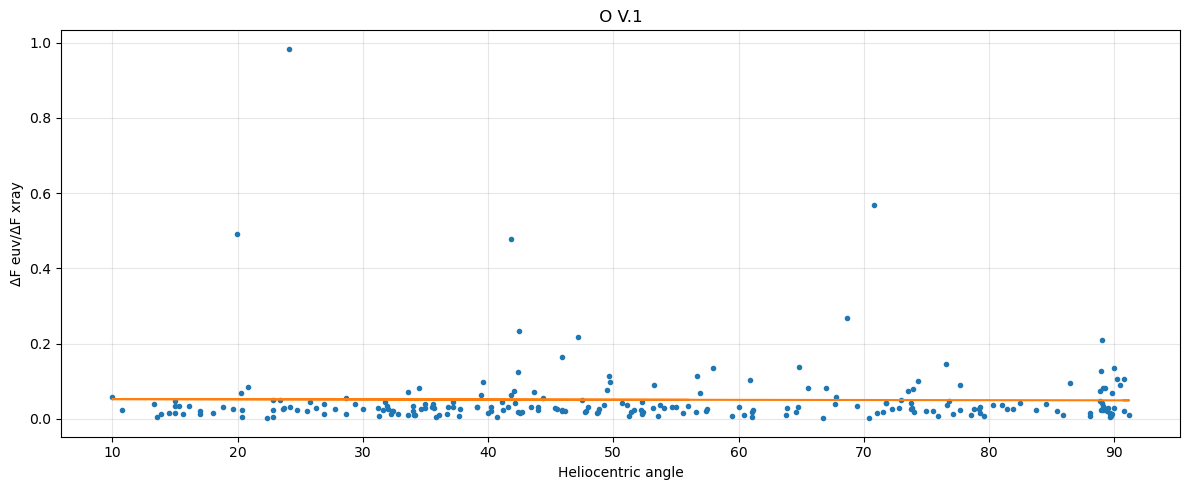

slope= -4e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


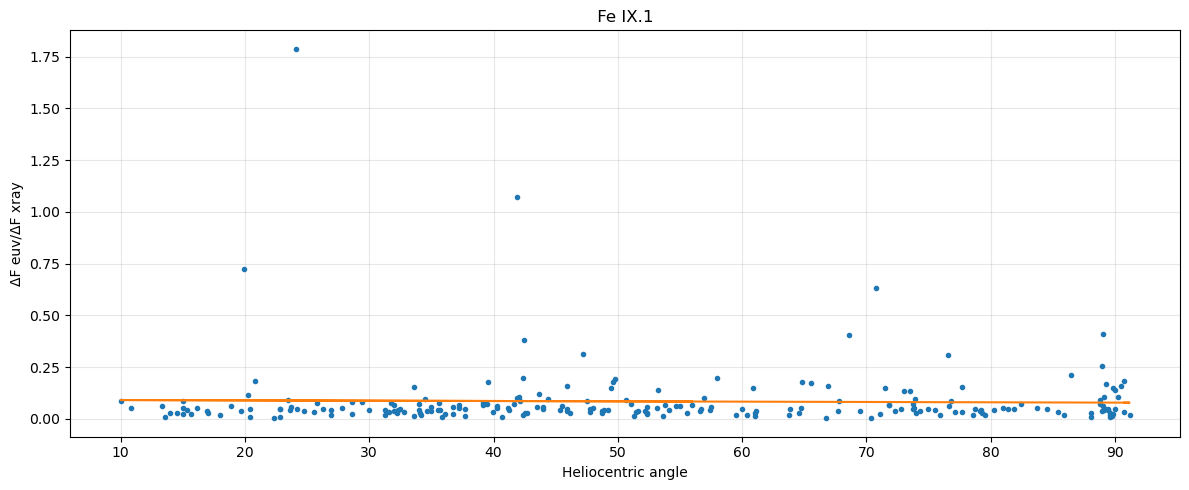

slope= -0.000156
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


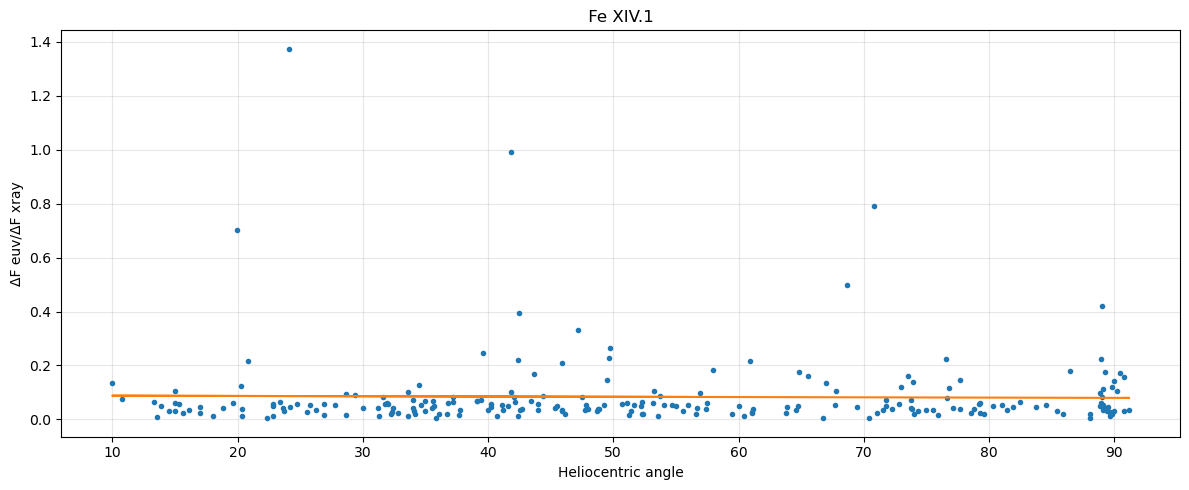

slope= -0.000102
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


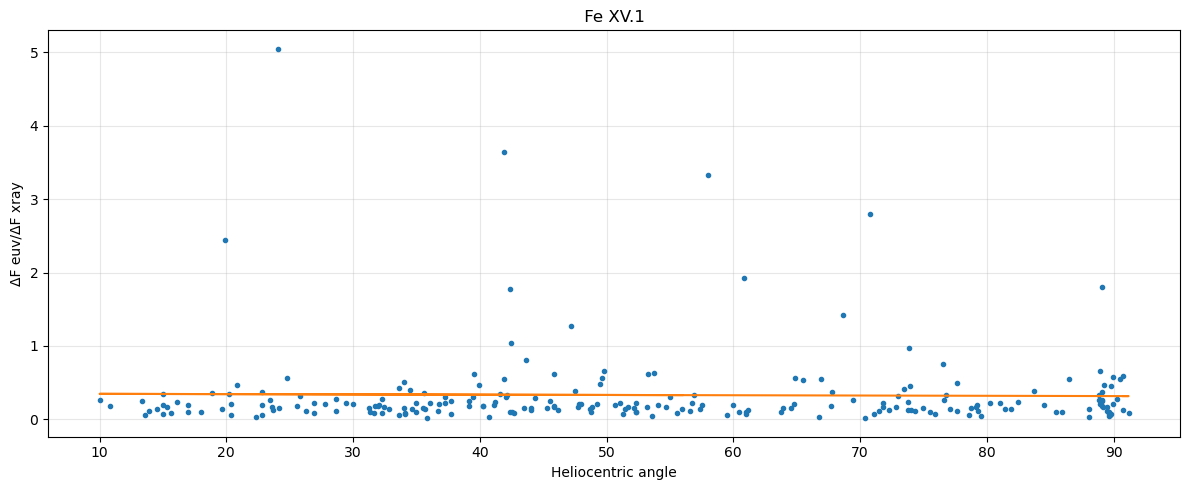

slope= -0.000381
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


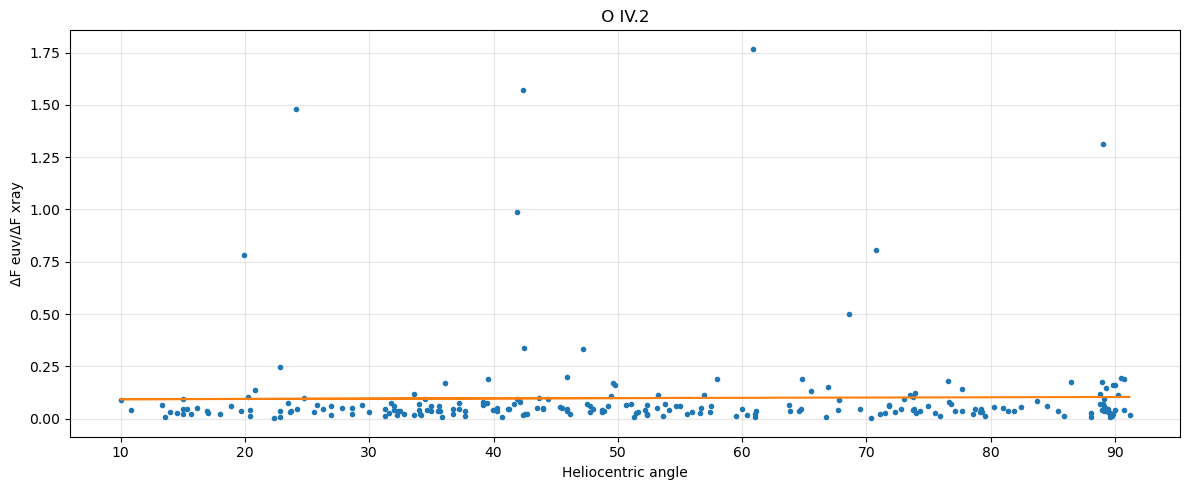

slope= 0.000134
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


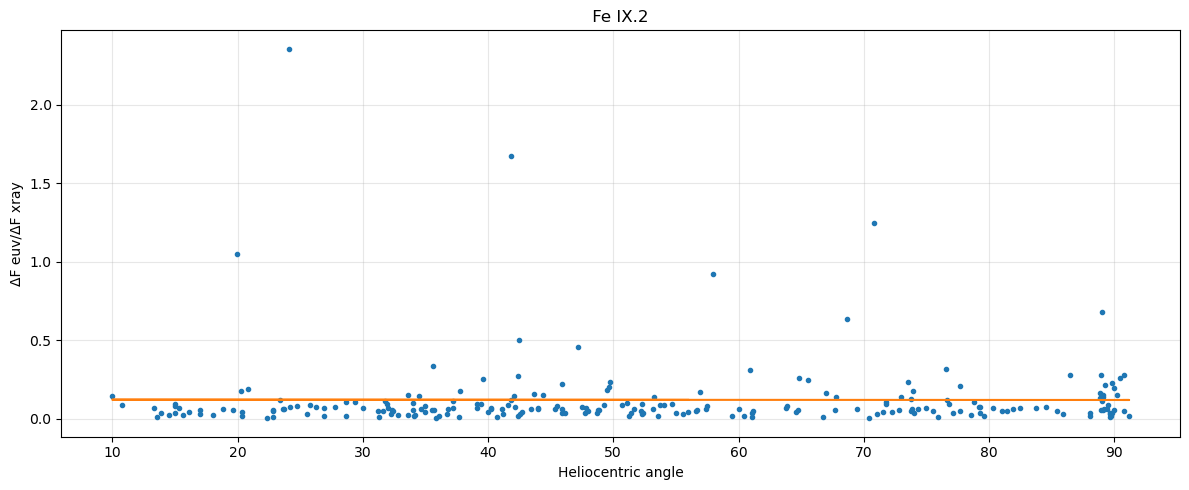

slope= -2.2e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


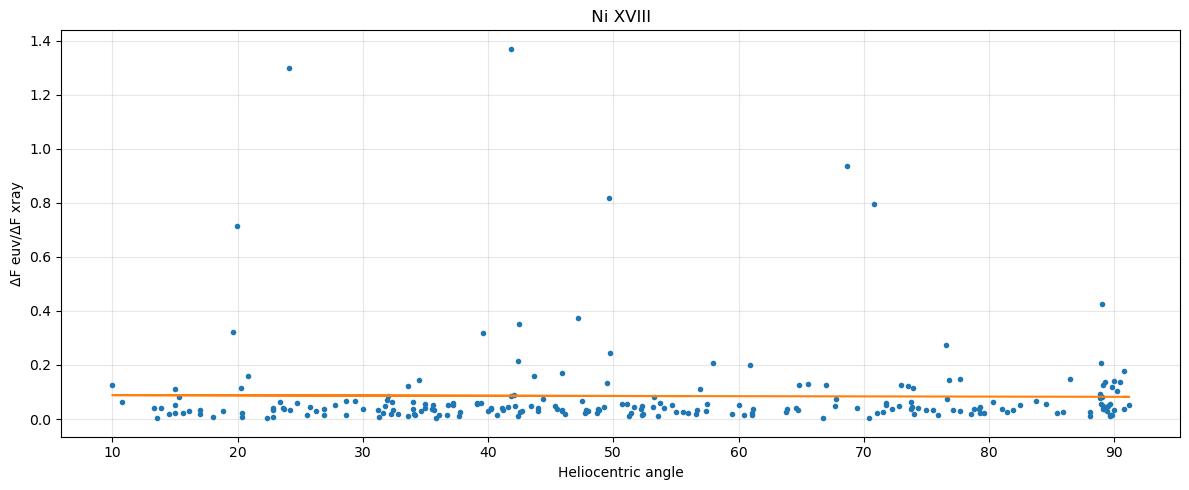

slope= -7.8e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


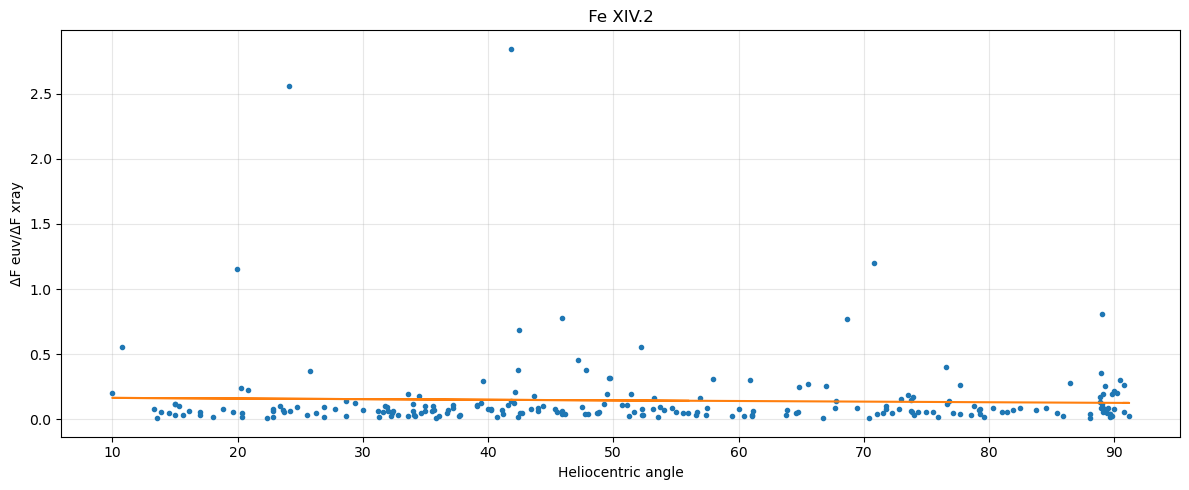

slope= -0.000477
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


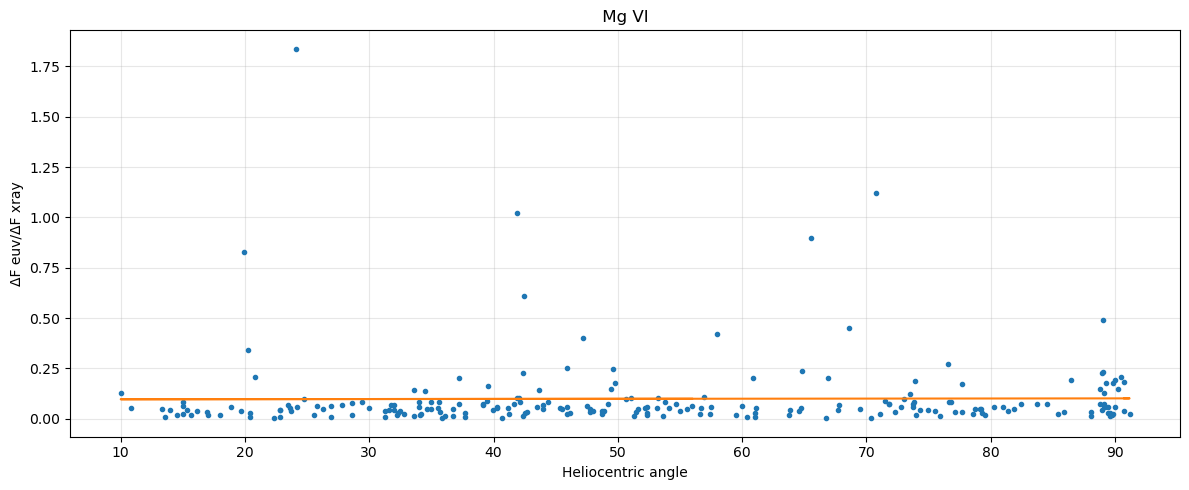

slope= 5.4e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


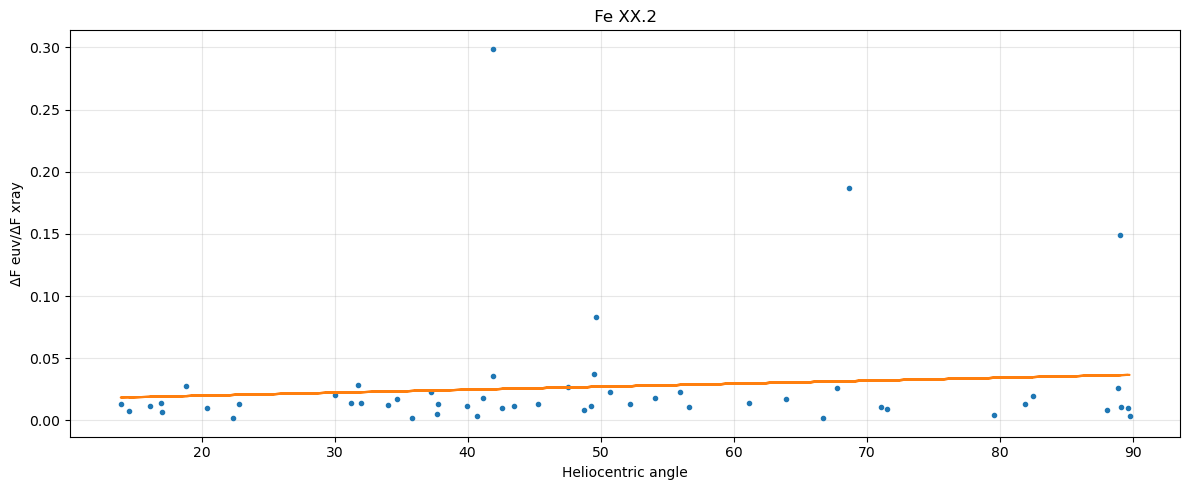

slope= 0.00024
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


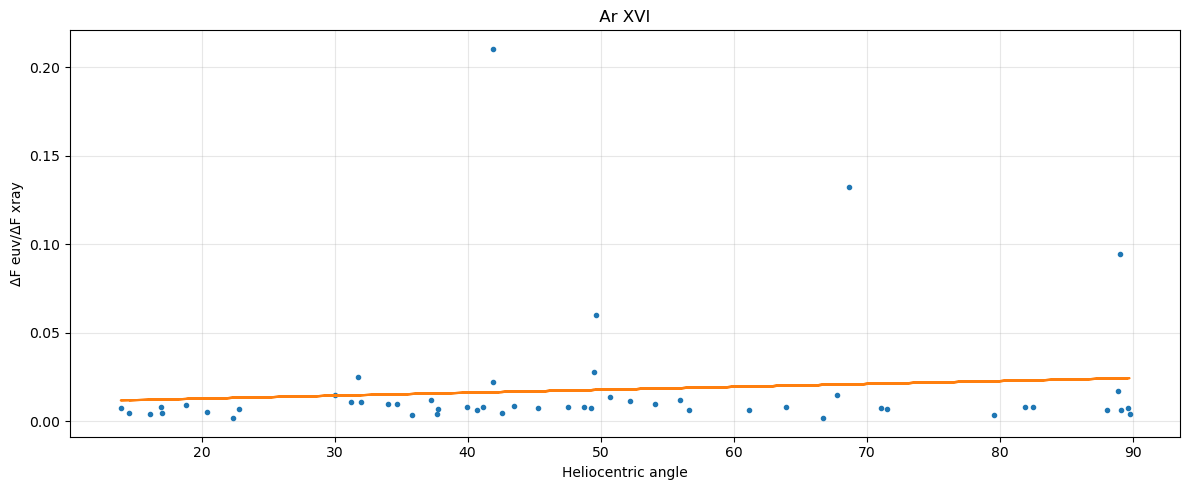

slope= 0.000166
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


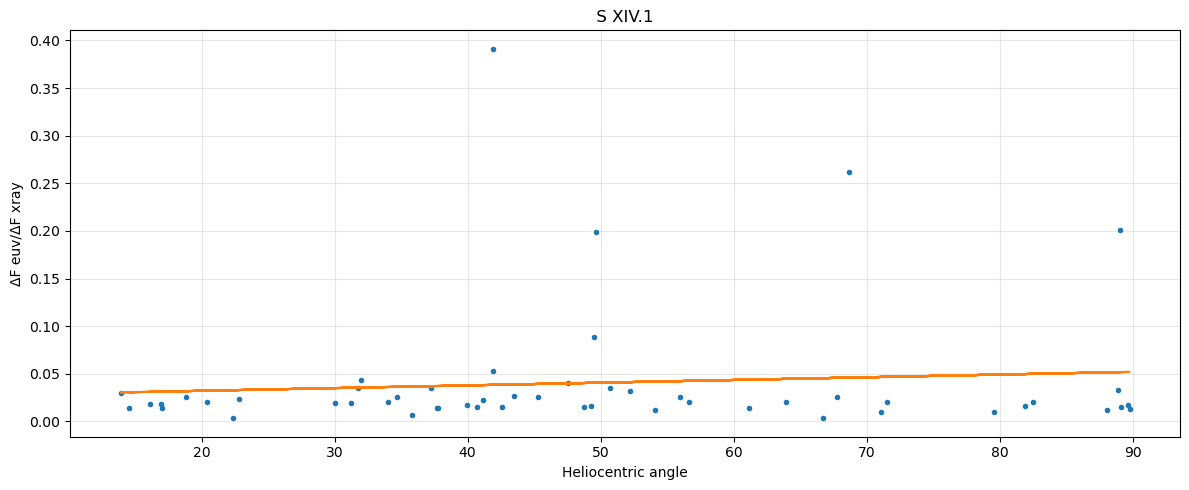

slope= 0.000284
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


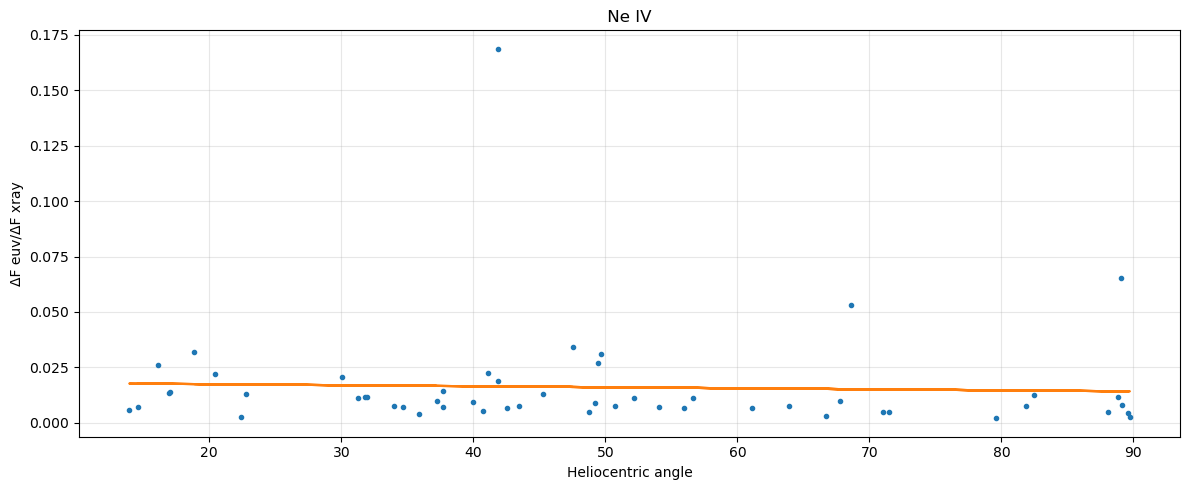

slope= -4.6e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


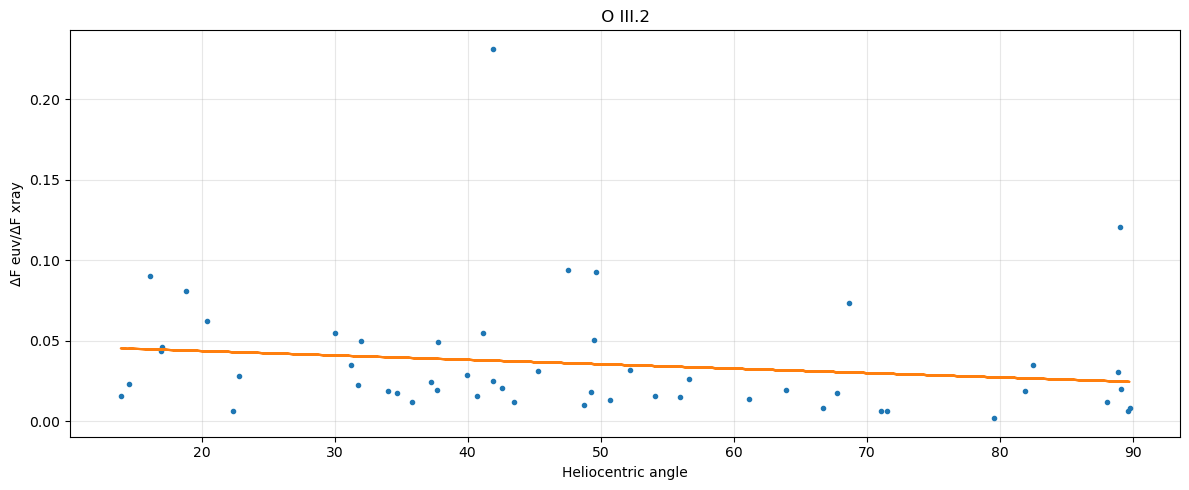

slope= -0.000273
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


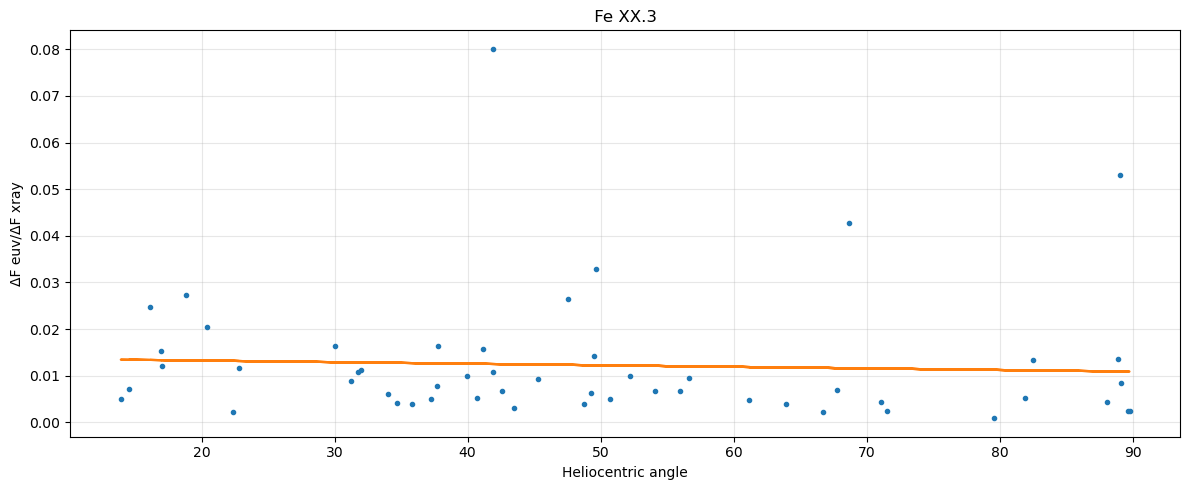

slope= -3.4e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


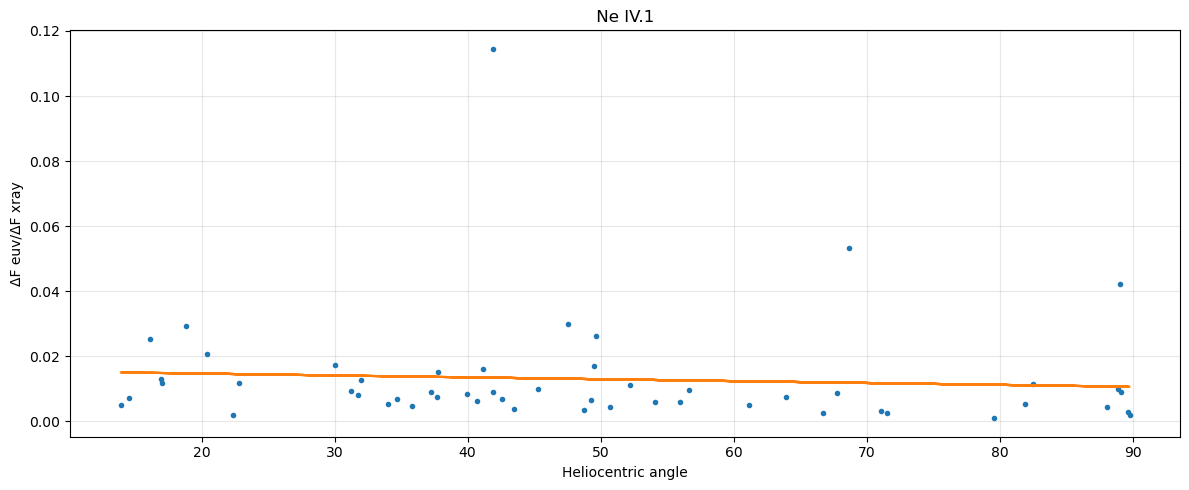

slope= -5.8e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


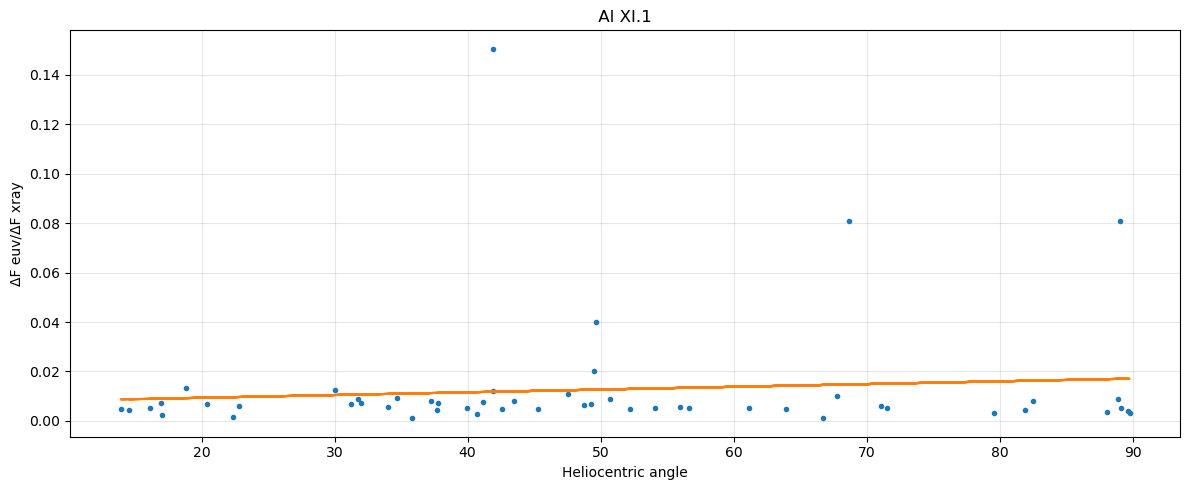

slope= 0.000111
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


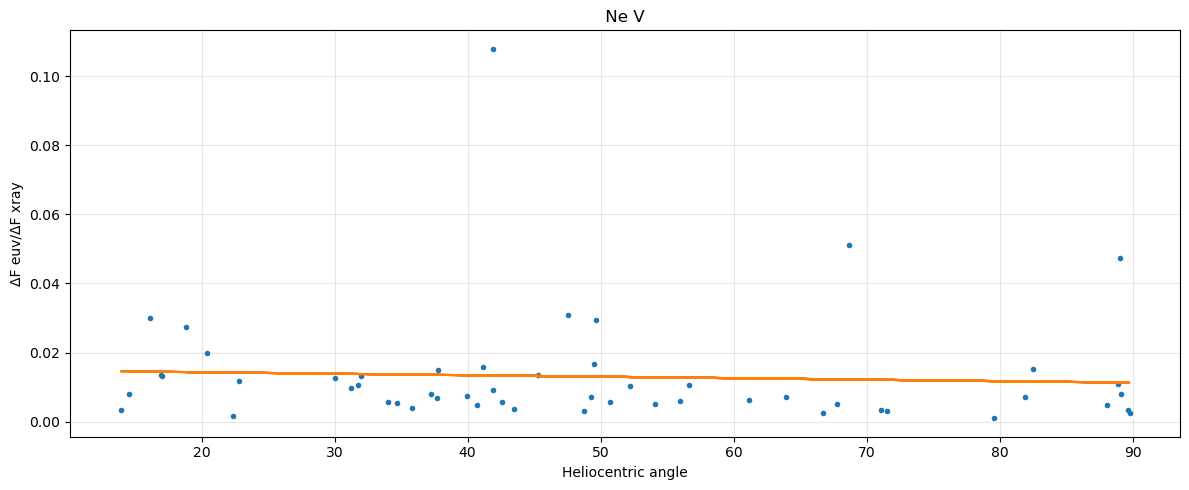

slope= -4.3e-05
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


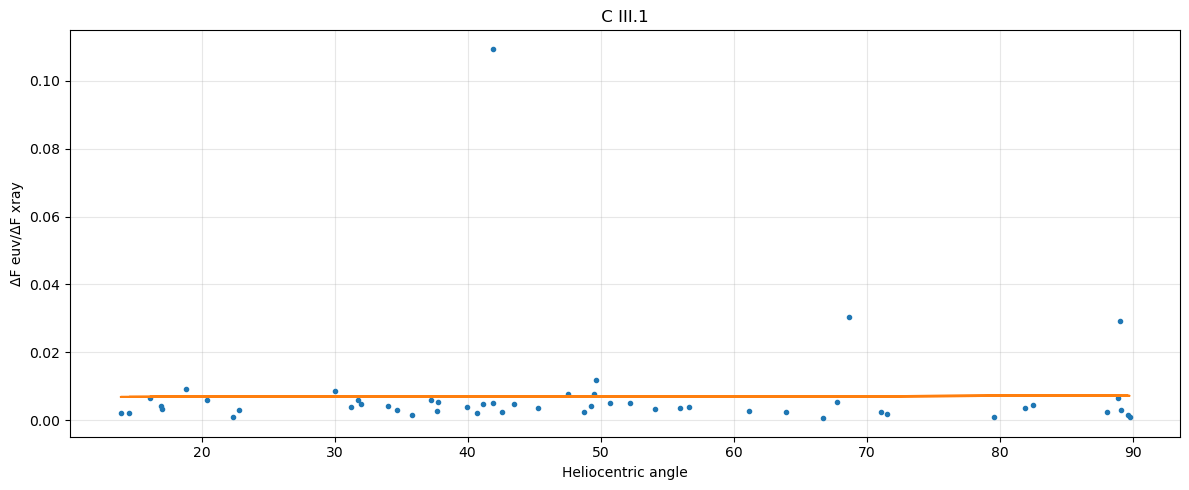

slope= 4e-06
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


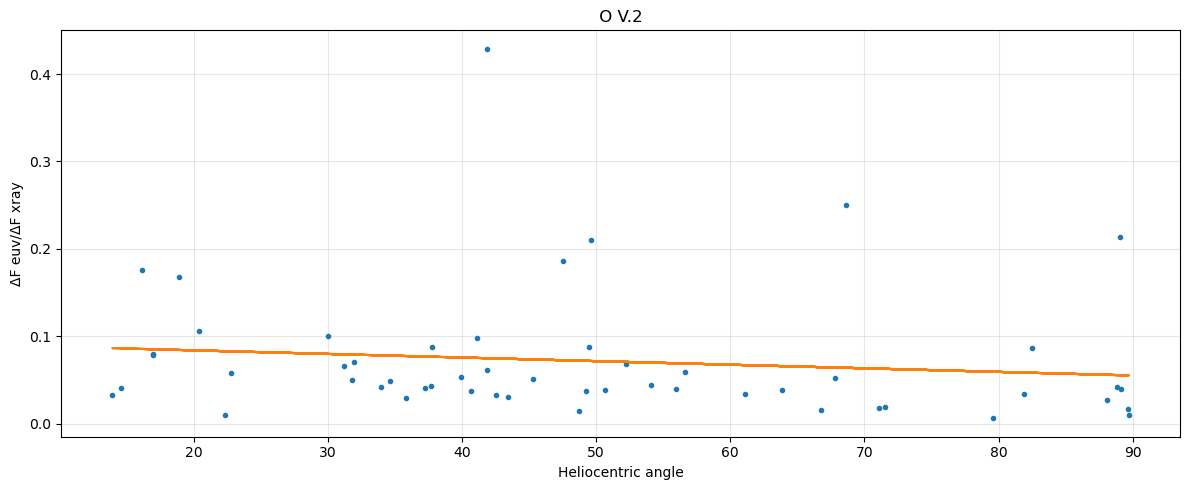

slope= -0.000411
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


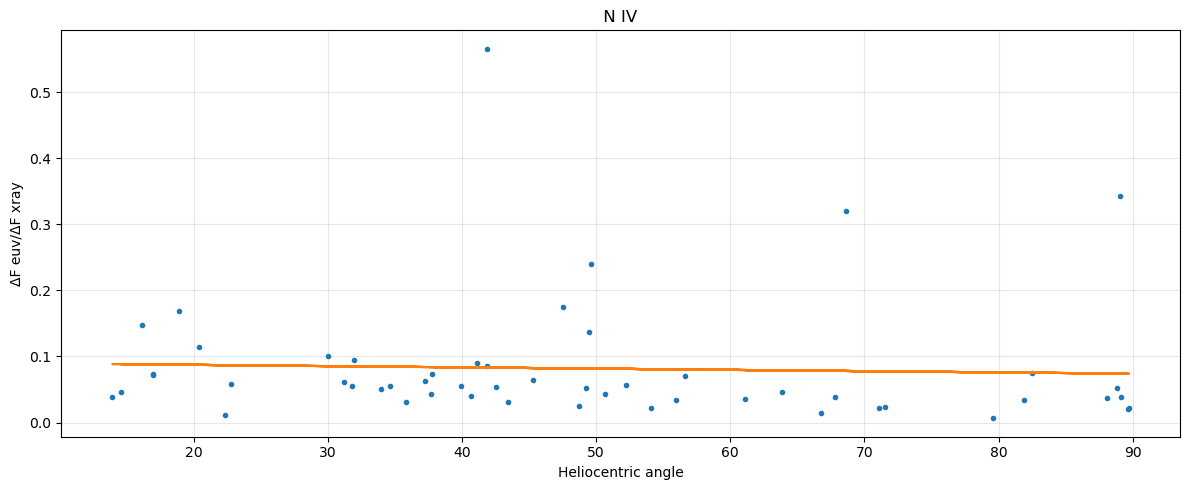

slope= -0.00019
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


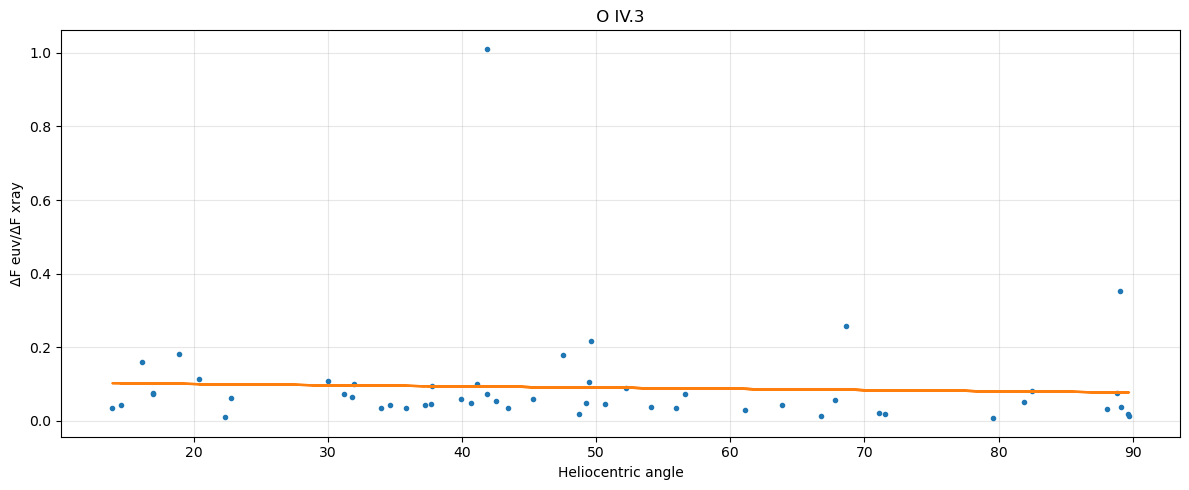

slope= -0.000328
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


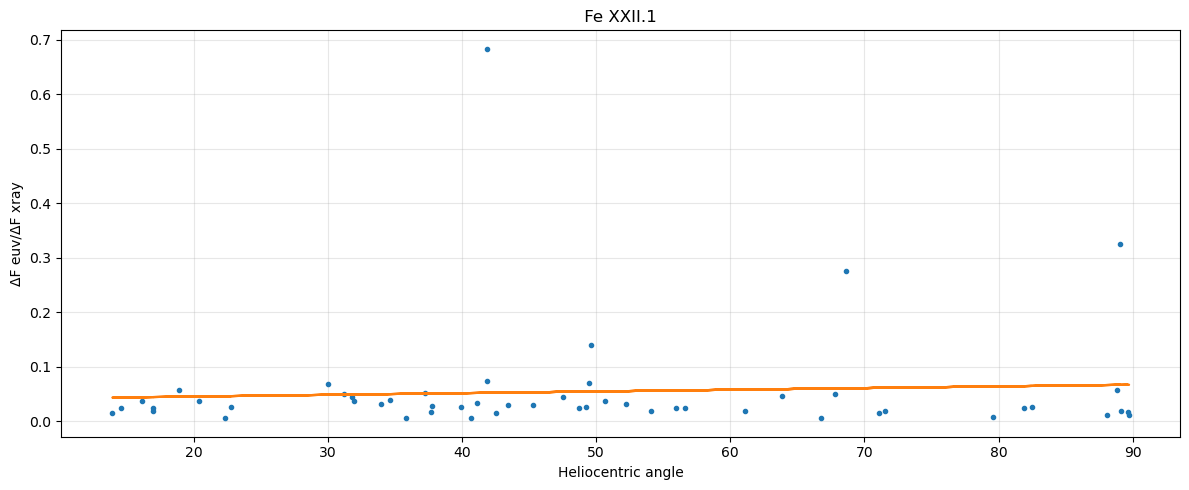

slope= 0.00031
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


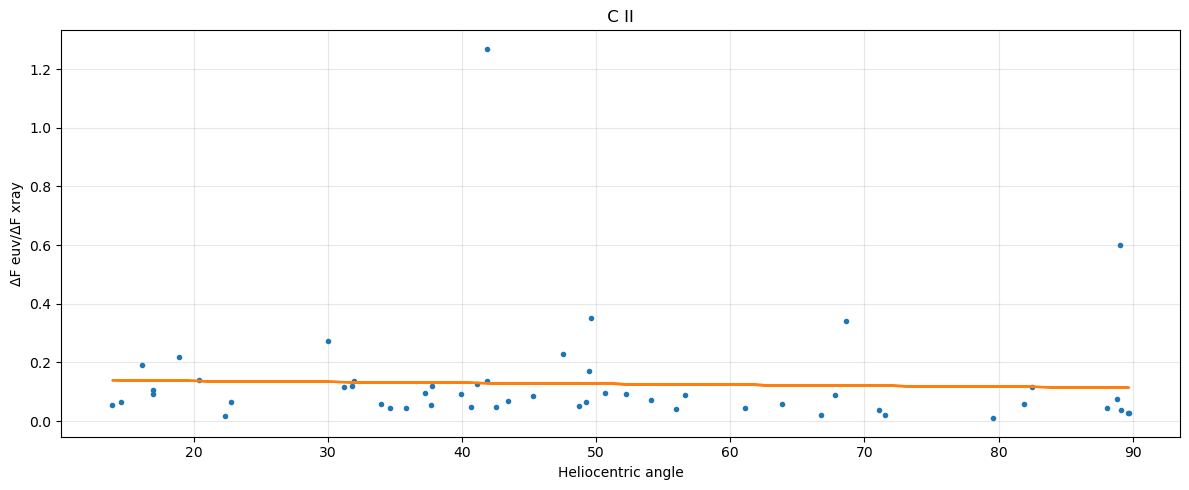

slope= -0.000326
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


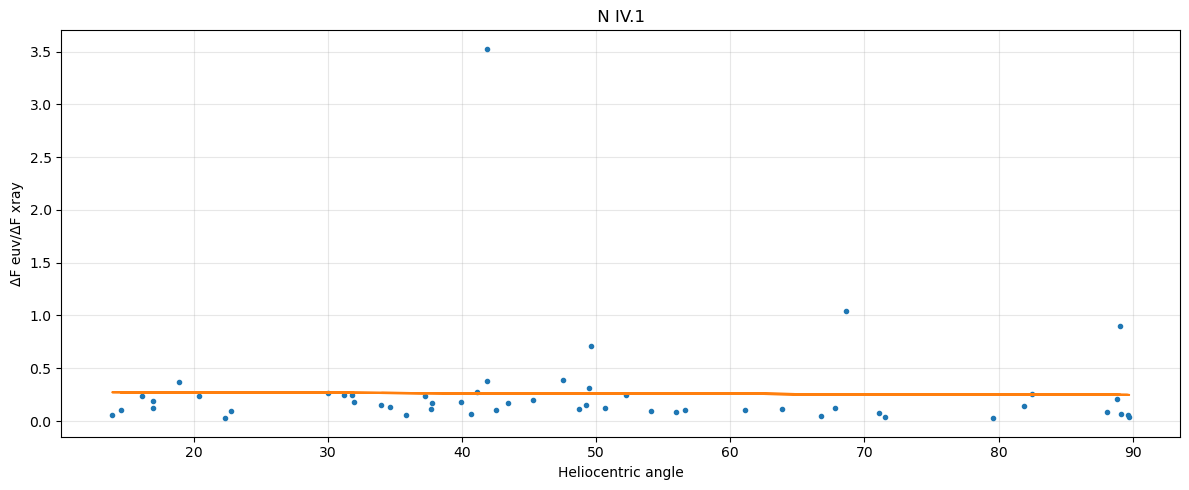

slope= -0.00033
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


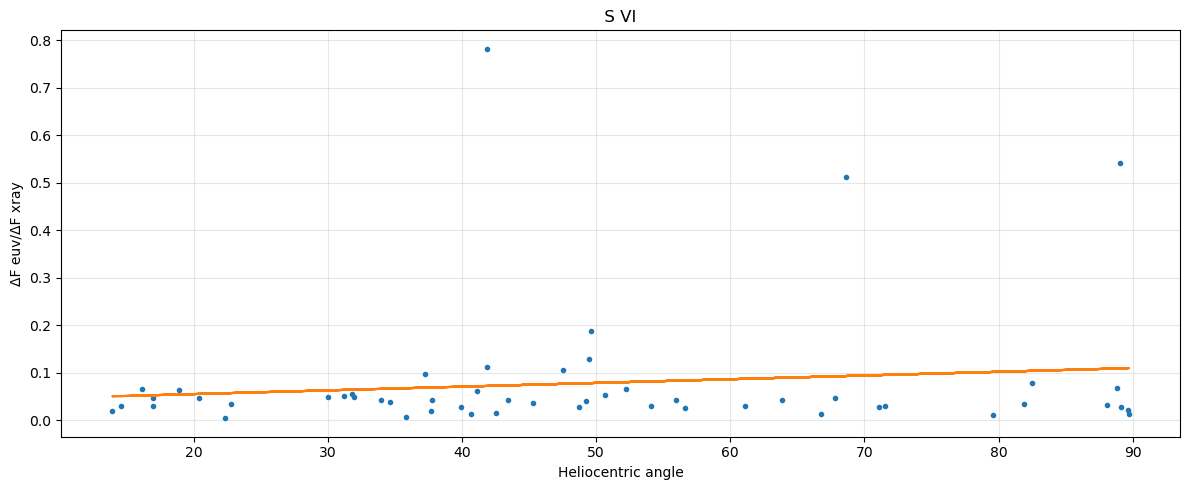

slope= 0.000782
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


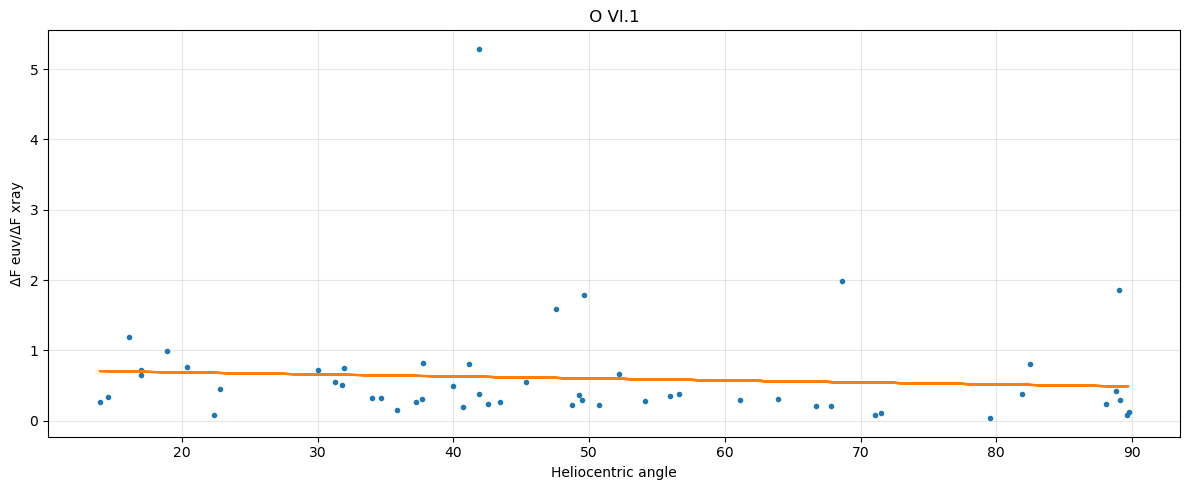

slope= -0.002853
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [65]:
softxraysflux=data_lists[titles[8]]
Heliocentric_angle=data_lists[titles[5]]
softxback=data_lists[titles[9]]

for i in range (10,81):   # for each wavelength
#for i in range (10,11):
    angle=[]
    ratio=[]
    emission_type_flux=data_lists[titles[i]]
    background=data_lists[titles[i+71]]
    for x in range(len(emission_type_flux)):
        if "dead" in data_lists[titles[4]][x]:
            if emission_type_flux[x]=='Nan' or softxraysflux[x] == 'Nan':
                pass
            else:
                ratio.append((float(emission_type_flux[x])-float(background[x]))/(softxraysflux[x]-softxback[x]))
                angle.append(Heliocentric_angle[x])

    plt.figure(figsize=(12, 5))
    plt.plot(angle, ratio,".",color="red")
    
    angle=[]
    ratio=[]
    
    for x in range(len(emission_type_flux)):
        if "." in data_lists[titles[4]][x]:
            if emission_type_flux[x]=='Nan' or softxraysflux[x] == 'Nan':
                pass
            else:
                ratio.append((float(emission_type_flux[x])-float(background[x]))/(softxraysflux[x]-softxback[x]))
                angle.append(Heliocentric_angle[x])
            

    plt.plot(angle, ratio,".")
    plt.xlabel("Heliocentric angle")
    #plt.xlim(start, end)
    plt.ylabel("ΔF euv/ΔF xray")
    plt.title(f" {titles[i]} " )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    slope, intercept,rvalue,pvalue,stderr =stats.linregress(angle, ratio)
    plt.plot(angle,slope*np.array(angle)+intercept)
    plt.show()
    print('slope=',round(slope,6))
    print('--'*100); print('--'*100); print('--'*100);
